# 02 — Treinamento, comparação e otimização de modelos (com MLflow)

**Entregáveis cobertos:**

| Item | Onde neste notebook |
|---|---|
| Baseline justificado, métricas em validação, MLflow | Seções 3 e 4 (regressão logística) |
| Pelo menos 3 modelos da lista (árvore de decisão, random forest, AdaBoost), visualizações, análise crítica, MLflow | Seções 4 a 6 |
| Otimização de hiperparâmetros (Optuna), MLflow | Seção 8 |
| Validação cruzada, estabilidade, overfitting/underfitting, generalização | Seção 7 |
| Modelo final salvo e registrado (insumo da API de inferência) | Seção 9 |
| Verificação complementar: árvores regularizadas (otimização) | Apêndice A |

**Entrada:** `processed/dataset_modelagem.csv` e `listas_de_variaveis.json`, gerados no notebook 01.
**Código compartilhado:** `src/preparacao.py` e `src/modelo.py` (o mesmo que o DAG do Airflow e a API vão usar).

**Como rodar:** `pip3 install -r requirements-ml.txt` (inclui `optuna`). Tempo total estimado: **30 a 45 minutos**; para reduzir, ajuste `N_TRIALS` (seção 8) e `RODAR_CURVA_APRENDIZADO` (seção 7).

## 1. Protocolo de avaliação (definido ANTES de comparar modelos)
O documento de entregáveis pede métricas previamente definidas. Fixamos aqui, antes de olhar qualquer resultado:

| Decisão | Escolha | Por quê |
|---|---|---|
| **Alvo** | `alagou_estrito` | Registro de "Alagamentos"/"Imóveis Alagados"; o rótulo amplo mistura monitoramento de rotina |
| **Cenário principal** | A — a chuva do dia é conhecida | É o que o sistema terá com um pluviômetro local ou previsão. O cenário B (sem ela) é avaliado ao final |
| **Métrica de seleção** | **PR-AUC** (*average precision*) | Só ~0,07% das linhas são positivas; a acurácia seria 99,9% prevendo "nunca alaga". A PR-AUC mede a qualidade do ranking para evento raro (um modelo aleatório teria ≈ 0,0007) |
| **Métricas operacionais** | recall e precisão nos **5% de maior risco** | Respondem: "se alertarmos 5% dos bairro-dias, quantos alagamentos pegamos e quantos alertas acertam?" |
| **Métricas operacionais (corte restrito)** | recall nos **1% de maior risco** | Um alerta mais seletivo: quanto dos alagamentos já aparece no topo da lista |
| **F1 da classe positiva** | F1 no corte de 5% | Resume recall e precisão num número só. Não usamos o F1 no corte 0,5: com probabilidades tão pequenas, quase nada passa de 0,5 e o F1 seria ~0 para todos os modelos |
| **Métrica complementar** | ROC-AUC | Ordenação global; otimista com classes raras, por isso não decide |
| **Corte da matriz de confusão** | Alertar os 5% de maior risco | Um corte operacional realista; a matriz exige um corte, e a probabilidade bruta é muito pequena para usar 0,5 |
| **Validação** | *Leave-one-year-out*: cada ano de 2014–2021 é testado por um modelo treinado nos outros 7 | Ver justificativa abaixo |
| **Teste cronológico (holdout)** | Treino 2014–2017, teste 2018–2021 | Separa o **futuro do passado**: o modelo só vê anos anteriores aos que vai prever, como no uso real, sem nenhuma informação do período de teste. Usado para medir, sem viés, o ganho da otimização de hiperparâmetros e no Apêndice A |
| **Regra de escolha do modelo** | O mais simples cuja PR-AUC não seja claramente pior que a do melhor (reamostragem de dias, 95%) | Com poucos eventos, diferenças pequenas são ruído; preferimos o modelo mais simples e explicável |

### Por que validação por ano e não *k-fold* estratificado
Os eventos se **agrupam em poucos dias de tempestade** (78 dias distintos concentram os 162 positivos). Num *k-fold* embaralhado, linhas do mesmo dia e do mesmo evento caem em treino e teste ao mesmo tempo, e o resultado fica **otimista**. A validação por ano respeita o tempo e é mais próxima do uso real. Na seção 7 mostramos o *k-fold* estratificado apenas como **contraste**.

### Por que não *Leave-One-Out*
A especificação pede *Leave-One-Out* (LOO) "quando aplicável". O LOO clássico deixa **uma linha** de fora por vez: treina com as demais, prevê a linha que ficou de fora e, no fim, calcula as métricas sobre todas as previsões juntas. Aqui ele **não é aplicável**, por dois motivos:
1. **Custo:** com ~220 mil linhas seriam ~220 mil treinos, cada um com praticamente o dataset inteiro, para cada modelo e de novo para cada tentativa do Optuna. Mesmo a regressão logística levaria dias.
2. **Vazamento (o motivo principal):** os 162 alagamentos se concentram em 78 dias de tempestade, e no mesmo dia vários bairros alagam juntos. Ao deixar de fora "bairro X no dia D", o treino continua vendo os outros bairros no mesmo dia D e os dias vizinhos: o modelo acerta por reconhecer o dia, não por saber prever. É o problema do *k-fold* embaralhado (seção 7.3) levado ao extremo, e o resultado seria otimista.

**O que aplicamos no lugar:** a variante do LOO **por grupos** (*leave-one-group-out*, `LeaveOneGroupOut` no scikit-learn), em que o grupo é o **ano**: cada ano é previsto por um modelo que nunca o viu. Mantém a ideia do LOO (cada parte é testada por um modelo treinado sem ela), sem o custo e sem o vazamento, porque o dia de tempestade inteiro fica fora do treino.

### "Resíduos" em classificação
Este é um problema de classificação binária; resíduos no sentido da regressão não se aplicam. Os equivalentes usados aqui são: **taxa observada por decil de risco** (calibração/ordenação), **eventos capturados e perdidos por ano** (erro) e **matriz de confusão**.

## 2. Configuração, MLflow e dados
O experimento é criado com o **local dos artefatos fixado na raiz do projeto** (`mlruns/`), para que o banco (`mlflow.db`) e os artefatos fiquem juntos.

In [1]:
import os, sys, json, hashlib, warnings, pathlib, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow, joblib, optuna
from mlflow.tracking import MlflowClient
from sklearn.metrics import roc_curve, precision_recall_curve

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60)

candidatos = [pathlib.Path("..").resolve(), pathlib.Path(".").resolve(), pathlib.Path("/Users/nhffbs/dados_alagamento")]
RAIZ = next(p for p in candidatos if (p / "processed" / "dataset_modelagem.csv").exists())
sys.path.insert(0, str(RAIZ / "src"))
import importlib, preparacao as prep, modelo as mod
importlib.reload(prep); importlib.reload(mod)

FIG_DIR = RAIZ / "relatorio_figuras"; FIG_DIR.mkdir(exist_ok=True)
MODELOS_DIR = RAIZ / "modelos"; MODELOS_DIR.mkdir(exist_ok=True)
ART_DIR = RAIZ / "processed" / "modelagem_artefatos"; ART_DIR.mkdir(exist_ok=True)

mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{RAIZ / 'mlflow.db'}"))
EXPERIMENTO = "alagamento_modelagem"
_cli = MlflowClient()
_exp = _cli.get_experiment_by_name(EXPERIMENTO)
_exp_id = _exp.experiment_id if _exp else mlflow.create_experiment(EXPERIMENTO, artifact_location=(RAIZ / "mlruns").as_uri())
mlflow.set_experiment(experiment_id=_exp_id)
if mlflow.active_run():
    mlflow.end_run()

def registrar_fig(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=130, bbox_inches="tight")
    if mlflow.active_run():
        mlflow.log_figure(fig, f"figuras/{nome}.png")
    plt.show()

def registrar_json(obj, nome):
    caminho = ART_DIR / nome
    caminho.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    if mlflow.active_run():
        mlflow.log_artifact(str(caminho), artifact_path="relatorios")

def registrar_tabela(df_, nome):
    caminho = ART_DIR / nome
    df_.to_csv(caminho)
    if mlflow.active_run():
        mlflow.log_artifact(str(caminho), artifact_path="relatorios")

def limpa(d):
    return {k: float(v) for k, v in d.items() if v is not None and not np.isnan(v)}

# o pickle do ModeloRisco referencia os modulos 'modelo' e 'preparacao': vao junto com o modelo para quem o carregar
CODIGO_MODELO = [str(RAIZ / "src" / "preparacao.py"), str(RAIZ / "src" / "modelo.py")]

def registrar_modelo(modelo, nome="modelo", exemplo=None):
    try:
        return mlflow.sklearn.log_model(modelo, name=nome, input_example=exemplo, code_paths=CODIGO_MODELO)
    except TypeError:                                     # versoes do MLflow sem o argumento 'name'
        return mlflow.sklearn.log_model(modelo, artifact_path=nome, input_example=exemplo, code_paths=CODIGO_MODELO)

DATA_PATH = RAIZ / "processed" / "dataset_modelagem.csv"
base = pd.read_csv(DATA_PATH, parse_dates=["data"])
listas = json.loads((RAIZ / "processed" / "eda_artefatos" / "listas_de_variaveis.json").read_text(encoding="utf-8"))
ALVO, FEATURES_A, FEATURES_B = listas["alvo_principal"], listas["features_A"], listas["features_B"]
SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()[:16]
y = base[ALVO].values
print(f"{len(base):,} linhas | alvo: {ALVO} | positivos: {int(y.sum())} | features A: {len(FEATURES_A)} (+ propensão do bairro) | B: {len(FEATURES_B)}")
display(base.groupby("ano")[ALVO].agg(linhas="size", positivos="sum").T)

PROTOCOLO = {"alvo": ALVO, "cenario_principal": "A (chuva do dia conhecida)", "cenario_secundario": "B (sem a chuva do dia)",
             "metrica_selecao": "pr_auc", "metricas_operacionais": ["recall_top5", "precisao_top5", "recall_top1", "f1_top5"], "metrica_complementar": "roc_auc",
             "corte_operacional": "alertar os 5% de maior risco", "validacao": "leave-one-year-out (2014-2021)",
             "teste_cronologico": "treino 2014-2017, teste 2018-2021",
             "regra_de_escolha": "modelo mais simples cuja PR-AUC nao seja claramente pior que a do melhor (bootstrap de dias, 95%)",
             "semente": mod.SEMENTE, "dataset_sha256_16": SHA}

2026/11/25 12:01:38 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/25 12:01:38 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


219,882 linhas | alvo: alagou_estrito | positivos: 162 | features A: 29 (+ propensão do bairro) | B: 25


ano,2014,2015,2016,2017,2018,2019,2020,2021
linhas,28080,28080,28080,26910,27300,28470,28548,24414
positivos,64,34,30,9,1,17,5,2


## 3. Referências sem aprendizado de máquina
Antes de treinar, medimos dois critérios simples. Eles dão o piso que um modelo precisa superar para justificar-se:
- **só chuva:** ordena os dias pela chuva;
- **chuva × bairro:** taxa de alagamento da faixa de chuva × propensão histórica do bairro (calculadas só com os anos de treino de cada rodada).

In [2]:
refs = mod.referencias(base, ALVO)
tab_refs = pd.DataFrame({n: mod.metricas(y, s) for n, s in refs.items()}).T
display(tab_refs[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5", "f1_top5"]].round(4))

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5,f1_top5
referencia: so chuva,0.0203,0.8370,0.4259,0.5123,0.0075,0.0149
referencia: chuva x bairro,0.0441,0.8416,0.4383,0.5926,0.0087,0.0172


## 4. Os modelos
| Modelo | Papel | Por quê |
|---|---|---|
| **Regressão logística** | **Baseline** (exigido pelo documento) | Simples, rápida e **interpretável** (cada variável tem um coeficiente). Tem poucos parâmetros, o que reduz o risco de decorar os poucos eventos. Compensa o desbalanceamento com `class_weight="balanced"` e regularização forte (`C=0,1`). Exige log nas chuvas, imputação e padronização |
| **Árvore de decisão** | 1º modelo da lista da especificação | O modelo de árvores mais simples e o mais explicável: vira um conjunto de regras "se chuva > X e faixa marginal > Y, então risco". Rasa (profundidade 5) e com folhas grandes (≥300 linhas), porque com ~160 eventos uma árvore profunda decora os positivos |
| **Floresta aleatória** | 2º modelo da lista | Modelo de árvores robusto | Capta não linearidades e interações sem muita sensibilidade a hiperparâmetros; a média de muitas árvores reduz a variância. Usamos profundidade limitada e folhas grandes (≥100 linhas) contra o sobreajuste |
| **AdaBoost** | 3º modelo da lista | *Boosting* clássico: cada árvore rasa (profundidade 2) foca nos exemplos que as anteriores erraram. Os positivos começam com peso maior (raiz do desbalanceamento), como no gradient boosting |
| **Gradient boosting** (`HistGradientBoosting`) | Modelo **adicional**, fora da lista (requer aval do professor) | Modelo de árvores sequencial | Costuma ser o mais forte em dados tabulares; aceita vazios nativamente. Positivos pesam a *raiz* do desbalanceamento (um peso integral causaria sobreajuste) |

A especificação pede um baseline e **pelo menos três modelos da lista** (KNN, árvore de decisão, random forest, AdaBoost, MLP): usamos árvore de decisão, random forest e AdaBoost. Ficaram de fora o KNN (lento em 220 mil linhas e sensível à escala de 29 variáveis heterogêneas) e o MLP (com ~160 positivos, uma rede tende a decorar e é pouco explicável). O gradient boosting é mantido como modelo adicional.

Todos recebem as mesmas variáveis (cenário A) mais a **propensão do bairro**, calculada sem o próprio ano (ver notebook 01). Cada modelo tem o preparo adequado a ele (`PREP_KW` em `src/modelo.py`).

In [3]:
def painel_modelo(titulo, yy, p, q=0.05):
    m = mod.metricas(yy, p)
    fig, ax = plt.subplots(2, 2, figsize=(11, 8))
    cm, corte = mod.confusao_topq(yy, p, q)
    a = ax[0, 0]; a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["previsto: não", "previsto: sim"])
    a.set_yticks([0, 1]); a.set_yticklabels(["real: não", "real: sim"])
    a.set_title(f"Matriz de confusão ({int(q*100)}% de maior risco em alerta)")
    fpr, tpr, _ = roc_curve(yy, p)
    ax[0, 1].plot(fpr, tpr); ax[0, 1].plot([0, 1], [0, 1], "--", color="gray")
    ax[0, 1].set_title(f"Curva ROC (AUC = {m['roc_auc']:.3f})"); ax[0, 1].set_xlabel("falsos positivos"); ax[0, 1].set_ylabel("recall")
    prec, rec, _ = precision_recall_curve(yy, p)
    ax[1, 0].plot(rec, prec); ax[1, 0].axhline(yy.mean(), ls="--", color="gray", label="acaso")
    ax[1, 0].set_title(f"Precisão × recall (PR-AUC = {m['pr_auc']:.3f})"); ax[1, 0].set_xlabel("recall"); ax[1, 0].set_ylabel("precisão"); ax[1, 0].legend()
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    taxa = pd.DataFrame({"y": yy, "d": dec.values}).groupby("d")["y"].mean() * 100
    ax[1, 1].bar(range(10), taxa.values, color="#c44e52"); ax[1, 1].set_yscale("symlog", linthresh=0.01)
    ax[1, 1].set_title("Taxa observada de alagamento por decil de risco (%)"); ax[1, 1].set_xlabel("decil (0 = menor risco, 9 = maior)")
    fig.suptitle(titulo, y=1.01); fig.tight_layout()
    return fig

def figura_erro_por_ano(titulo, oof, q=0.05):
    corte = np.quantile(oof["p"].values, 1 - q)
    g = oof.assign(capturados=((oof["p"] >= corte) & (oof["y"] == 1)).astype(int),
                   perdidos=((oof["p"] < corte) & (oof["y"] == 1)).astype(int)).groupby("ano")[["capturados", "perdidos"]].sum()
    fig, ax = plt.subplots(figsize=(7, 3.5))
    g.plot(kind="bar", stacked=True, ax=ax, color=["#55a868", "#c44e52"])
    ax.set_title(titulo); ax.set_ylabel("eventos"); ax.set_xlabel("")
    return fig

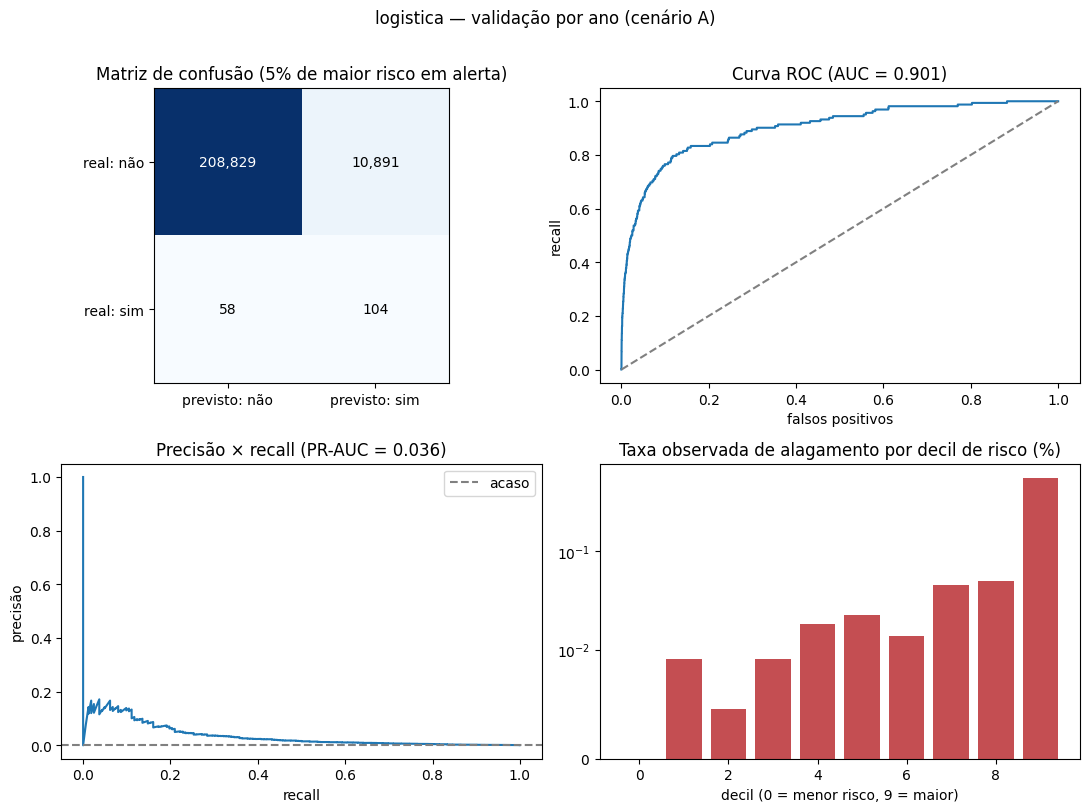

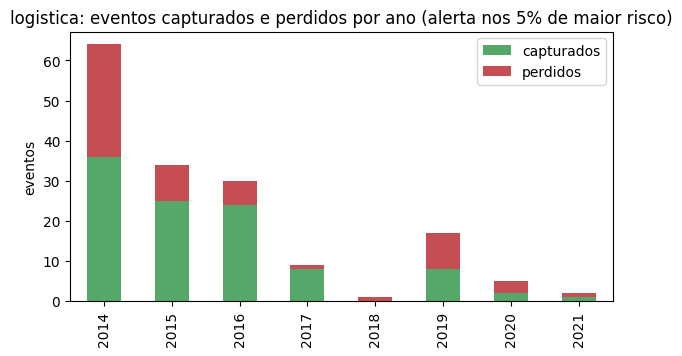

logistica  PR-AUC=0.0360  ROC-AUC=0.9014  recall@top5%=0.642  precisão@top5%=0.0095


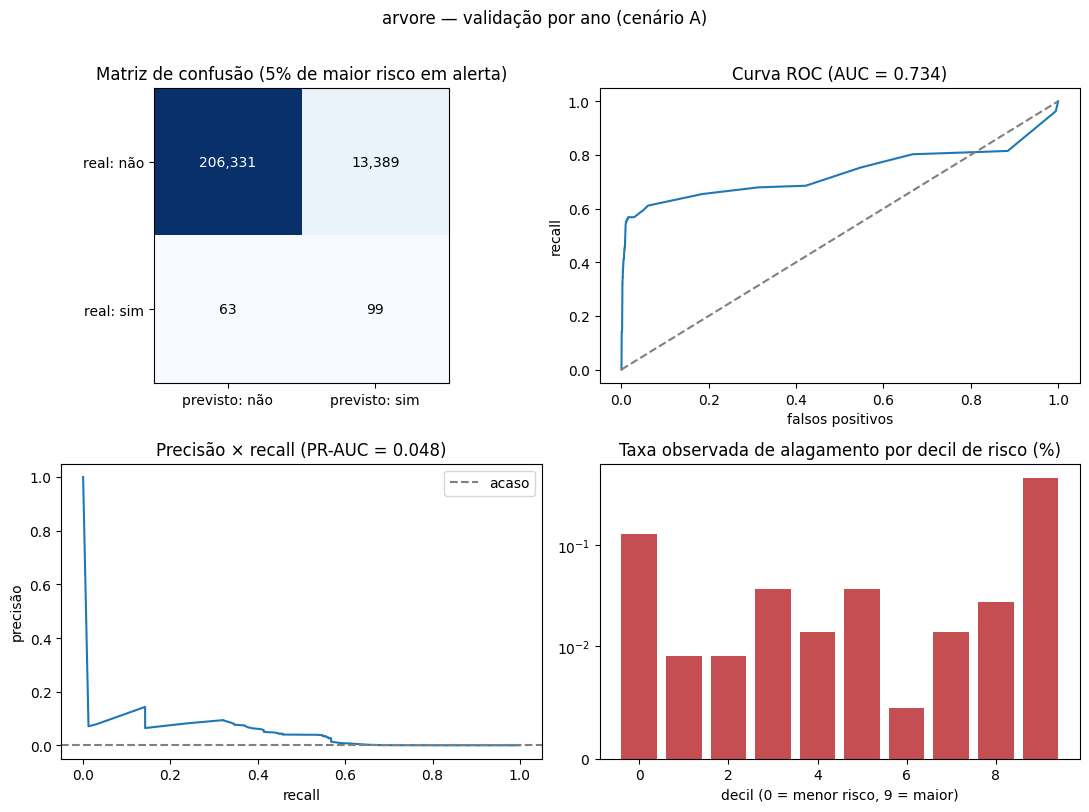

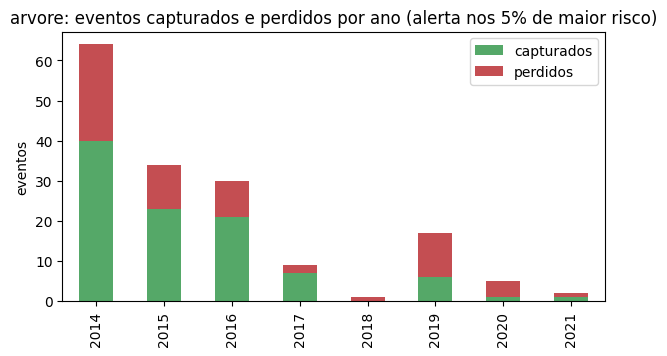

arvore     PR-AUC=0.0477  ROC-AUC=0.7335  recall@top5%=0.599  precisão@top5%=0.0088


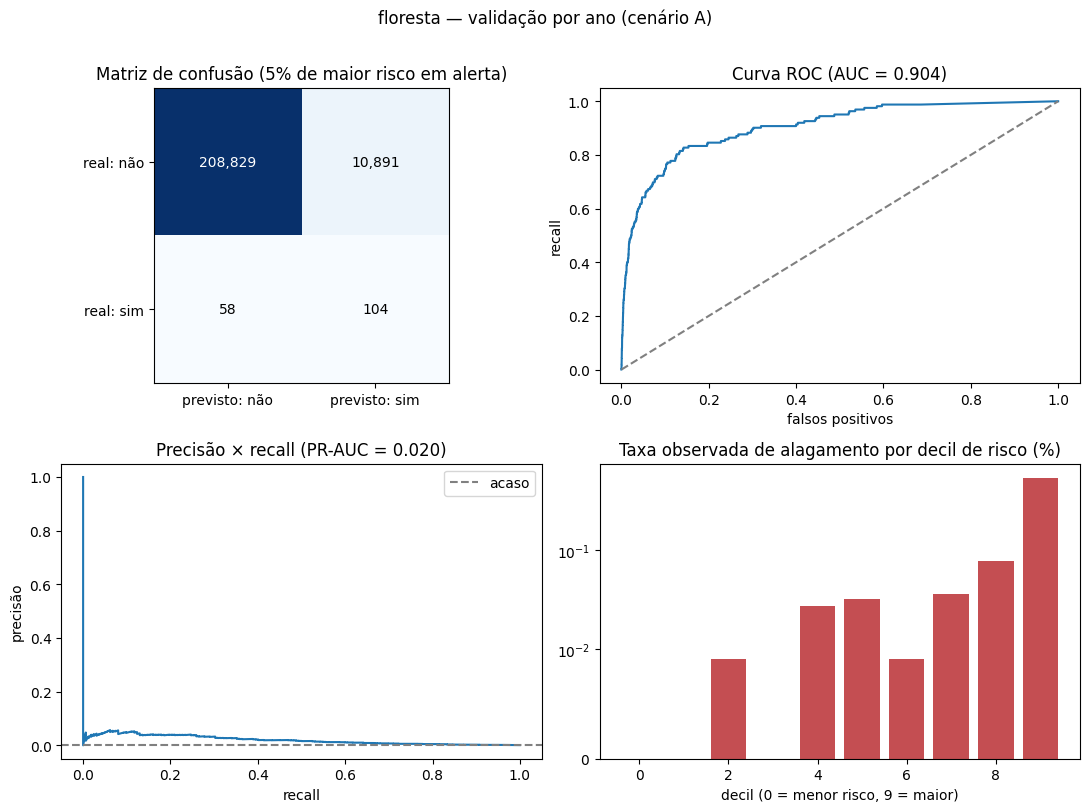

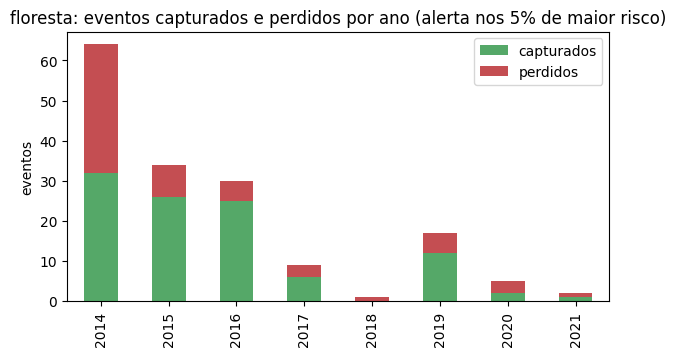

floresta   PR-AUC=0.0203  ROC-AUC=0.9039  recall@top5%=0.642  precisão@top5%=0.0095


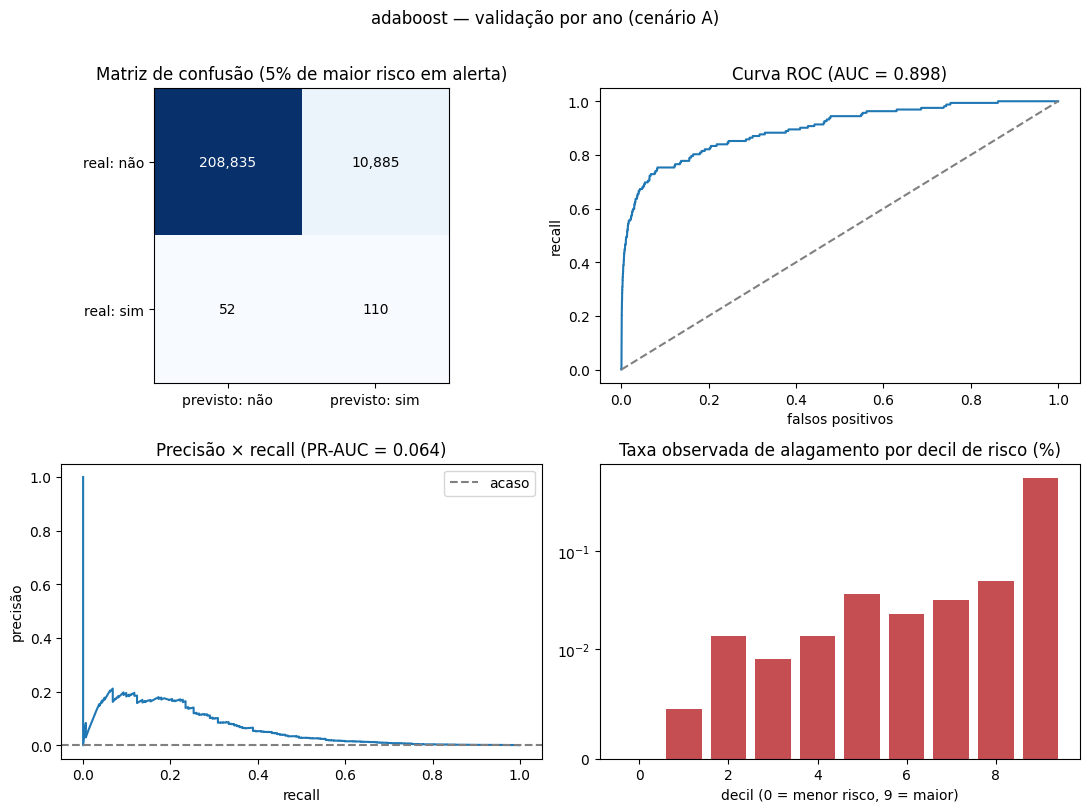

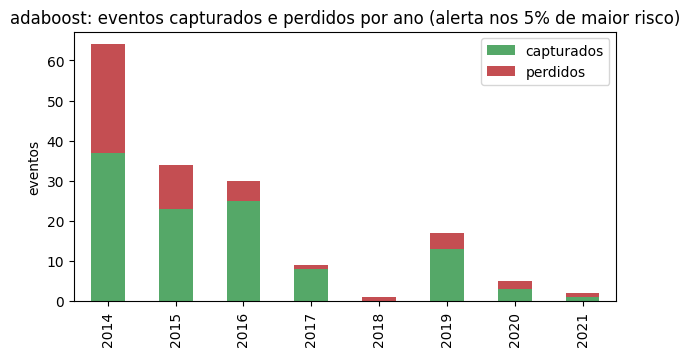

adaboost   PR-AUC=0.0638  ROC-AUC=0.8977  recall@top5%=0.679  precisão@top5%=0.0100


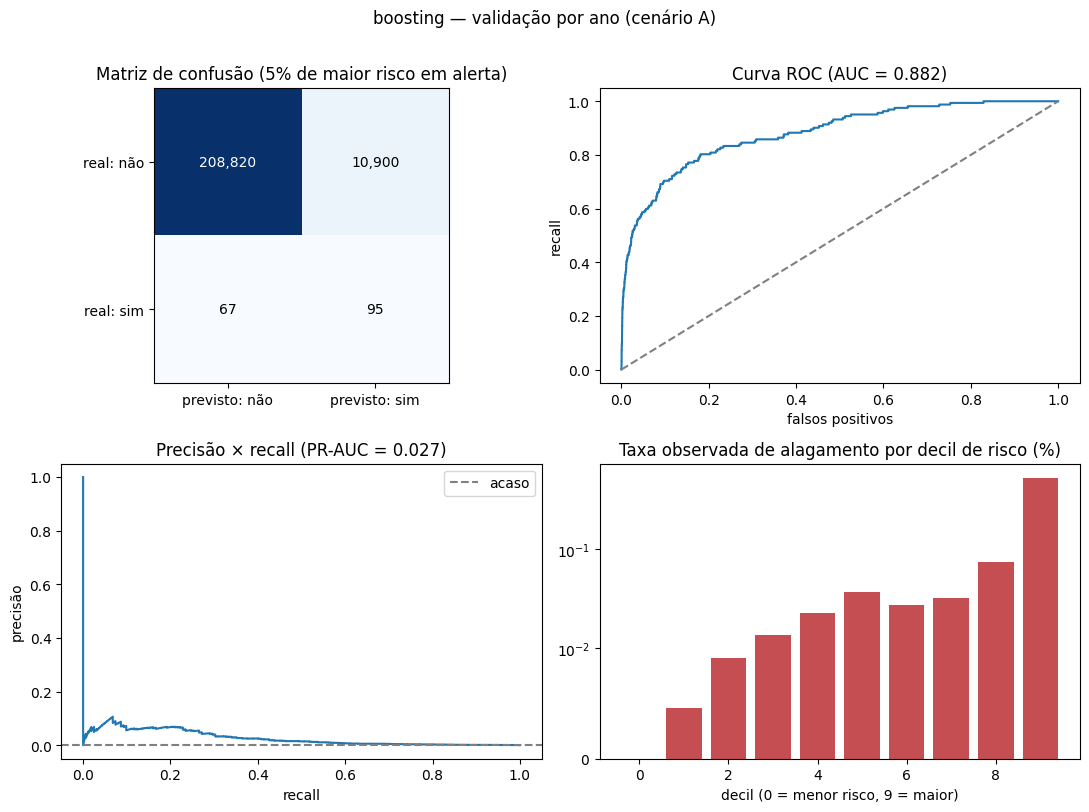

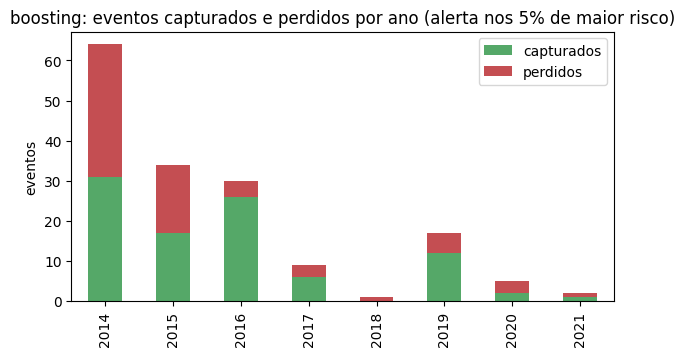

boosting   PR-AUC=0.0269  ROC-AUC=0.8819  recall@top5%=0.586  precisão@top5%=0.0086


In [4]:
resultados, run_ids = {}, {}
for nome in mod.COMPLEXIDADE:
    res = mod.validar_loyo(base, ALVO, FEATURES_A, nome, calcular_treino=True)
    resultados[nome] = res
    oof_ = res["oof"].loc[base.index]
    with mlflow.start_run(run_name=f"{nome}_cenarioA") as r:
        run_ids[nome] = r.info.run_id
        mlflow.set_tags({"etapa": "comparacao_modelos", "cenario": "A", "modelo": nome})
        mlflow.log_params({**{f"hp_{k}": v for k, v in res["params"].items()}, "alvo": ALVO,
                           "validacao": "leave-one-year-out", "n_features": len(FEATURES_A) + 1, "dataset_sha256_16": SHA})
        mlflow.log_metrics(limpa(res["global"]))
        for ano, row in res["por_ano"].iterrows():
            for met in ("pr_auc", "recall_top5"):
                if not np.isnan(row[met]):
                    mlflow.log_metric(f"{met}_por_ano", float(row[met]), step=int(ano))
        t = res["treino"]
        mlflow.log_metrics({"treino_pr_auc_medio": float(t["pr_auc"].mean()), "treino_roc_auc_medio": float(t["roc_auc"].mean()),
                            "treino_recall_top5_medio": float(t["recall_top5"].mean())})
        oof_.to_csv(ART_DIR / f"oof_{nome}.csv.gz")
        mlflow.log_artifact(str(ART_DIR / f"oof_{nome}.csv.gz"), artifact_path="previsoes")
        registrar_fig(painel_modelo(f"{nome} — validação por ano (cenário A)", oof_["y"].values, oof_["p"].values), f"painel_{nome}")
        registrar_fig(figura_erro_por_ano(f"{nome}: eventos capturados e perdidos por ano (alerta nos 5% de maior risco)", oof_), f"erro_por_ano_{nome}")
    g = res["global"]
    print(f"{nome:10s} PR-AUC={g['pr_auc']:.4f}  ROC-AUC={g['roc_auc']:.4f}  recall@top5%={g['recall_top5']:.3f}  precisão@top5%={g['precisao_top5']:.4f}")

## 5. Comparação dos modelos
Tabela, curvas sobrepostas e erro por ano. Em seguida, **intervalos de confiança por reamostragem de dias inteiros** (os eventos se agrupam por tempestade, então reamostrar linhas soltas subestimaria a incerteza) e a **regra de escolha** do protocolo.

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5,f1_top5
logistica,0.0360,0.9014,0.3642,0.6420,0.0095,0.0186
arvore,0.0477,0.7335,0.5370,0.5988,0.0088,0.0174
floresta,0.0203,0.9039,0.3519,0.6420,0.0095,0.0186
adaboost,0.0638,0.8977,0.4691,0.6790,0.0100,0.0197
boosting,0.0269,0.8819,0.3642,0.5864,0.0086,0.0170
referencia: so chuva,0.0203,0.8370,0.4259,0.5123,0.0075,0.0149
referencia: chuva x bairro,0.0441,0.8416,0.4383,0.5926,0.0087,0.0172


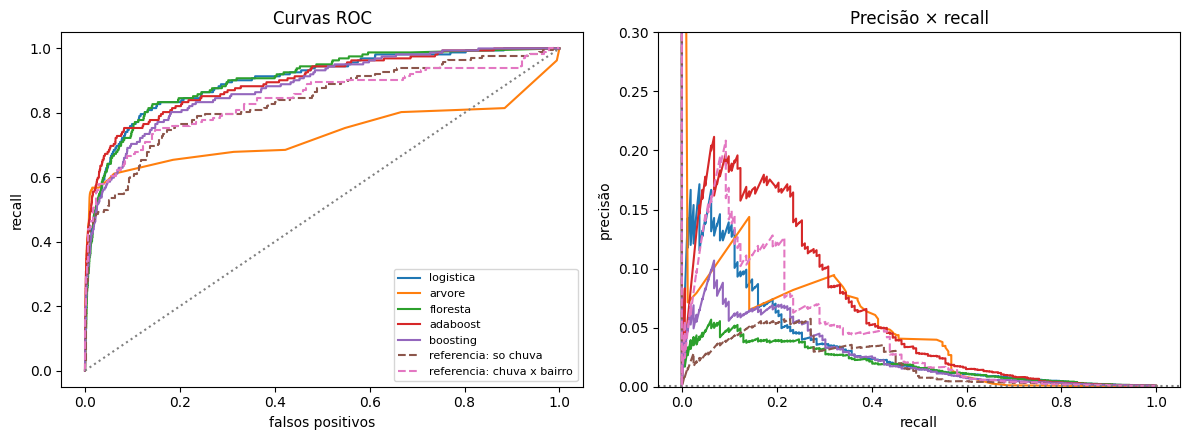

,logistica,arvore,floresta,adaboost,boosting,positivos
ano,,,,,,
2014,0.500,0.594,0.516,0.531,0.484,64
2015,0.559,0.676,0.618,0.676,0.529,34
2016,0.733,0.700,0.833,0.833,0.867,30
2017,0.889,0.556,0.667,0.889,0.667,9
2018,0.000,0.000,0.000,0.000,0.000,1
2019,0.588,0.412,0.706,0.765,0.706,17
2020,0.400,0.200,0.400,0.600,0.400,5
2021,0.500,0.500,0.500,0.500,0.500,2


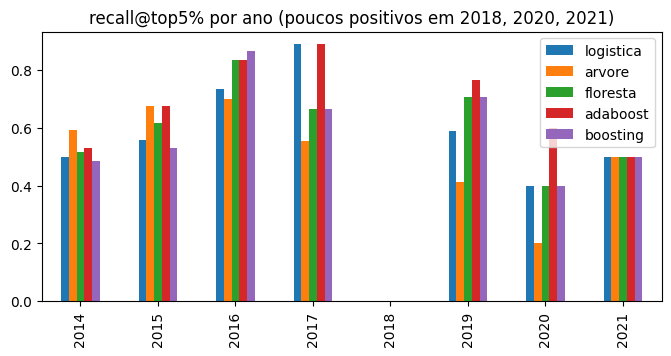

PR-AUC (reamostragem de dias)


,media,IC95 inf,IC95 sup
logistica,0.0405,0.0183,0.0750
arvore,0.0510,0.0250,0.0823
floresta,0.0221,0.0110,0.0400
adaboost,0.0693,0.0317,0.1272
boosting,0.0294,0.0124,0.0582
referencia: so chuva,0.0220,0.0111,0.0344
referencia: chuva x bairro,0.0482,0.0180,0.0894


recall@top5%


,media,IC95 inf,IC95 sup
logistica,0.637,0.541,0.713
arvore,0.592,0.488,0.678
floresta,0.637,0.525,0.731
adaboost,0.677,0.558,0.762
boosting,0.577,0.454,0.674
referencia: so chuva,0.515,0.369,0.653
referencia: chuva x bairro,0.590,0.464,0.697



Melhor PR-AUC média: adaboost | modelo escolhido pela regra de parcimônia: logistica
  adaboost − logistica: diferença média +0.0288 | adaboost ganha em 92% das reamostras
  adaboost − arvore: diferença média +0.0183 | adaboost ganha em 91% das reamostras
  adaboost − floresta: diferença média +0.0472 | adaboost ganha em 100% das reamostras
  adaboost − boosting: diferença média +0.0399 | adaboost ganha em 100% das reamostras


In [5]:
scores = {n: resultados[n]["oof"].loc[base.index, "p"].values for n in mod.COMPLEXIDADE}
todos = {**scores, **refs}
tab = pd.DataFrame({n: mod.metricas(y, s) for n, s in todos.items()}).T
display(tab[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5", "f1_top5"]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, s in todos.items():
    estilo = "--" if n.startswith("referencia") else "-"
    fpr, tpr, _ = roc_curve(y, s); ax[0].plot(fpr, tpr, estilo, label=n)
    prec, rec, _ = precision_recall_curve(y, s); ax[1].plot(rec, prec, estilo, label=n)
ax[0].plot([0, 1], [0, 1], ":", color="gray"); ax[0].set_title("Curvas ROC"); ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("recall"); ax[0].legend(fontsize=8)
ax[1].axhline(y.mean(), ls=":", color="gray"); ax[1].set_title("Precisão × recall"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisão"); ax[1].set_ylim(0, 0.3)
fig.tight_layout()

with mlflow.start_run(run_name="comparacao_modelos") as r_comp:
    run_comp = r_comp.info.run_id
    mlflow.set_tags({"etapa": "comparacao_modelos", "cenario": "A"})
    registrar_json(PROTOCOLO, "protocolo_de_avaliacao.json")
    registrar_tabela(tab, "comparacao_modelos.csv")
    registrar_fig(fig, "comparacao_curvas")

    rec_ano = pd.DataFrame({n: resultados[n]["por_ano"]["recall_top5"] for n in mod.COMPLEXIDADE})
    rec_ano["positivos"] = resultados[mod.COMPLEXIDADE[0]]["por_ano"]["positivos"]
    display(rec_ano.round(3))
    fig2, ax2 = plt.subplots(figsize=(8, 3.5))
    rec_ano[mod.COMPLEXIDADE].plot(kind="bar", ax=ax2); ax2.set_title("recall@top5% por ano (poucos positivos em 2018, 2020, 2021)"); ax2.set_xlabel("")
    registrar_fig(fig2, "comparacao_recall_por_ano")

    ap_b, rc_b = mod.bootstrap_dias(base["data"].values, y, todos, B=200)
    def resumo(d):
        return pd.DataFrame({n: {"media": v.mean(), "IC95 inf": np.percentile(v, 2.5), "IC95 sup": np.percentile(v, 97.5)} for n, v in d.items()}).T
    print("PR-AUC (reamostragem de dias)"); display(resumo(ap_b).round(4))
    print("recall@top5%"); display(resumo(rc_b).round(3))
    registrar_tabela(resumo(ap_b), "bootstrap_pr_auc.csv"); registrar_tabela(resumo(rc_b), "bootstrap_recall_top5.csv")

    # regra de escolha: do mais simples ao mais complexo, o primeiro que o melhor nao supera de forma clara
    medias = {n: ap_b[n].mean() for n in mod.COMPLEXIDADE}
    melhor = max(medias, key=medias.get)
    escolhido = melhor
    for n in mod.COMPLEXIDADE:
        if n == melhor:
            break
        if (ap_b[melhor] - ap_b[n] > 0).mean() < 0.95:
            escolhido = n
            break
    MODELO_ESCOLHIDO_MANUAL = None            # defina "logistica", "floresta" ou "boosting" para sobrescrever a regra
    if MODELO_ESCOLHIDO_MANUAL:
        escolhido = MODELO_ESCOLHIDO_MANUAL
    mlflow.set_tags({"modelo_melhor_pr_auc": melhor, "modelo_escolhido": escolhido})
    mlflow.log_metrics({f"pr_auc_{n}": float(medias[n]) for n in medias})

print(f"\nMelhor PR-AUC média: {melhor} | modelo escolhido pela regra de parcimônia: {escolhido}")
for n in mod.COMPLEXIDADE:
    if n != melhor:
        d = ap_b[melhor] - ap_b[n]
        print(f"  {melhor} − {n}: diferença média {d.mean():+.4f} | {melhor} ganha em {100*(d > 0).mean():.0f}% das reamostras")

### Tabela final: média e desvio de cada métrica
Cada ano deixado de fora é uma rodada (*fold*) da validação. A tabela mostra a **média ± desvio padrão entre os anos** de cada métrica, para cada modelo e para as referências sem ML. Entram só os anos com **pelo menos 5 eventos** (2014, 2015, 2016, 2017, 2019 e 2020): em 2018 (1 evento) e 2021 (2 eventos) as métricas viram ruído (um único acerto ou erro muda o recall de 0% para 100%). A última coluna repete a PR-AUC calculada com todas as previsões juntas, que é a usada na regra de escolha.

Em seguida, a mesma reamostragem de dias da seção anterior responde: **em quantas reamostras cada modelo supera cada referência?**

In [6]:
METRICAS_TAB = ["pr_auc", "roc_auc", "recall_top1", "precisao_top1", "f1_top1", "recall_top5", "precisao_top5", "f1_top5"]
MIN_POSITIVOS_ANO = 5
anos_ok = [a for a, g in base.groupby("ano") if g[ALVO].sum() >= MIN_POSITIVOS_ANO]
medias_ano, desvios_ano = {}, {}
for n, s in todos.items():
    por_ano_n = pd.DataFrame({a: mod.metricas(y[(base["ano"] == a).values], s[(base["ano"] == a).values]) for a in anos_ok}).T
    medias_ano[n], desvios_ano[n] = por_ano_n[METRICAS_TAB].mean(), por_ano_n[METRICAS_TAB].std()
medias_ano, desvios_ano = pd.DataFrame(medias_ano).T, pd.DataFrame(desvios_ano).T
tab_final = pd.DataFrame({m: [f"{medias_ano.loc[n, m]:.3f} ± {desvios_ano.loc[n, m]:.3f}" for n in todos] for m in METRICAS_TAB}, index=list(todos))
tab_final["pr_auc (agregada)"] = tab.loc[list(todos), "pr_auc"].round(4).values
tab_final.index = [f"{n}  ← escolhido" if n == escolhido else n for n in tab_final.index]
print(f"Média ± desvio entre os anos {anos_ok}")
display(tab_final)

vs_ref = pd.DataFrame({r_: {n: 100 * (ap_b[n] - ap_b[r_] > 0).mean() for n in mod.COMPLEXIDADE} for r_ in refs}).round(0)
vs_ref.columns = [f"% reamostras com PR-AUC > {c.replace('referencia: ', '')}" for c in vs_ref.columns]
display(vs_ref)
with mlflow.start_run(run_id=run_comp):
    registrar_tabela(pd.concat({"media": medias_ano, "desvio": desvios_ano}, axis=1), "tabela_final_media_desvio.csv")
    registrar_tabela(vs_ref, "modelos_vs_referencias.csv")

Média ± desvio entre os anos [2014, 2015, 2016, 2017, 2019, 2020]


,pr_auc,roc_auc,recall_top1,precisao_top1,f1_top1,recall_top5,precisao_top5,f1_top5,pr_auc (agregada)
logistica ← escolhido,0.044 ± 0.039,0.911 ± 0.035,0.313 ± 0.131,0.029 ± 0.023,0.050 ± 0.038,0.612 ± 0.175,0.011 ± 0.008,0.022 ± 0.015,0.0360
arvore,0.049 ± 0.038,0.741 ± 0.087,0.428 ± 0.188,0.043 ± 0.035,0.077 ± 0.060,0.523 ± 0.188,0.011 ± 0.010,0.022 ± 0.019,0.0477
floresta,0.043 ± 0.046,0.919 ± 0.031,0.342 ± 0.240,0.035 ± 0.031,0.061 ± 0.052,0.623 ± 0.151,0.012 ± 0.008,0.023 ± 0.016,0.0203
adaboost,0.128 ± 0.083,0.909 ± 0.044,0.438 ± 0.179,0.045 ± 0.038,0.078 ± 0.063,0.716 ± 0.138,0.013 ± 0.008,0.025 ± 0.016,0.0638
boosting,0.075 ± 0.073,0.896 ± 0.056,0.372 ± 0.194,0.035 ± 0.030,0.061 ± 0.050,0.609 ± 0.170,0.011 ± 0.008,0.022 ± 0.015,0.0269
referencia: so chuva,0.034 ± 0.020,0.864 ± 0.085,0.407 ± 0.161,0.039 ± 0.029,0.068 ± 0.048,0.486 ± 0.193,0.010 ± 0.008,0.019 ± 0.014,0.0203
referencia: chuva x bairro,0.099 ± 0.057,0.894 ± 0.049,0.421 ± 0.155,0.042 ± 0.033,0.074 ± 0.056,0.588 ± 0.233,0.011 ± 0.009,0.022 ± 0.016,0.0441


,% reamostras com PR-AUC > so chuva,% reamostras com PR-AUC > chuva x bairro
logistica,94.0,32.0
arvore,100.0,62.0
floresta,52.0,1.0
adaboost,100.0,96.0
boosting,79.0,3.0


**Escolha do modelo final: regressão logística.** O AdaBoost tem a maior média em quase todas as métricas (PR-AUC 0,128 ± 0,083 por ano e 0,064 agregada), mas **não vence de forma clara**:
- O protocolo, fixado antes de treinar, manda escolher o modelo **mais simples** cuja PR-AUC não seja claramente pior que a do melhor. O AdaBoost supera a logística em 92% das reamostras de dias, abaixo dos 95% exigidos. Os intervalos se sobrepõem bastante (logística 0,018–0,075; AdaBoost 0,032–0,127).
- Os desvios entre os anos são do mesmo tamanho das médias (PR-AUC 0,044 ± 0,039 na logística): com 162 eventos, boa parte da diferença entre modelos é ruído de quais anos tiveram tempestades.
- No teste cronológico (treino 2014–2017, teste 2018–2021) a vantagem do AdaBoost **some**: a PR-AUC dele cai para 0,011, enquanto a logística otimizada fica em 0,033 (seção 8 e importância das variáveis).
- A logística tem o **menor sobreajuste** (diferença treino × validação de 0,009 na PR-AUC, contra 0,12 do AdaBoost; seção 7.1) e é a mais fácil de explicar: cada variável tem um coeficiente com sinal.

Em ROC-AUC e recall nos 5%, a logística empata com os melhores (0,911 ± 0,035 e 0,612 ± 0,175).

## 6. Análise crítica
Primeiro, um resumo gerado a partir dos números; depois, onde o modelo escolhido falha e as respostas às perguntas de interpretação.

In [7]:
g = {n: resultados[n]["global"] for n in mod.COMPLEXIDADE}
r_chuva, r_cb = tab.loc["referencia: so chuva"], tab.loc["referencia: chuva x bairro"]
linhas_txt = [f"- Maior PR-AUC entre os modelos: **{melhor}** ({medias[melhor]:.4f}); modelo escolhido pela regra de parcimônia: **{escolhido}**.",
              "- PR-AUC / recall@top5% por modelo: " + "; ".join(f"{n} {g[n]['pr_auc']:.4f} / {g[n]['recall_top5']:.1%}" for n in mod.COMPLEXIDADE)
              + f" (baseline: {mod.BASELINE}; modelo adicional fora da lista: {mod.MODELO_ADICIONAL}).",
              f"- Referências sem ML: 'só chuva' PR-AUC {r_chuva['pr_auc']:.4f} (recall@top5% {r_chuva['recall_top5']:.1%}); "
              f"'chuva × bairro' PR-AUC {r_cb['pr_auc']:.4f} (recall@top5% {r_cb['recall_top5']:.1%}).",
              f"- A taxa base é {y.mean():.4%}: a PR-AUC dos modelos equivale a {max(g[n]['pr_auc'] for n in g)/y.mean():.0f} vezes o acaso, "
              f"mas a precisão@top5% é de apenas {max(g[n]['precisao_top5'] for n in g):.2%}, ou seja, a maioria dos alertas não coincide com um registro de alagamento."]
from IPython.display import Markdown
display(Markdown("\n".join(linhas_txt)))

- Maior PR-AUC entre os modelos: **adaboost** (0.0693); modelo escolhido pela regra de parcimônia: **logistica**.
- PR-AUC / recall@top5% por modelo: logistica 0.0360 / 64.2%; arvore 0.0477 / 59.9%; floresta 0.0203 / 64.2%; adaboost 0.0638 / 67.9%; boosting 0.0269 / 58.6% (baseline: logistica; modelo adicional fora da lista: boosting).
- Referências sem ML: 'só chuva' PR-AUC 0.0203 (recall@top5% 51.2%); 'chuva × bairro' PR-AUC 0.0441 (recall@top5% 59.3%).
- A taxa base é 0.0737%: a PR-AUC dos modelos equivale a 87 vezes o acaso, mas a precisão@top5% é de apenas 1.00%, ou seja, a maioria dos alertas não coincide com um registro de alagamento.

In [8]:
# onde o modelo escolhido falha: eventos capturados x perdidos no corte de 5% (validacao por ano)
oof_e = resultados[escolhido]["oof"].loc[base.index]
corte_e = np.quantile(oof_e["p"].values, 0.95)
ev = base.loc[oof_e["y"].values == 1, ["data", "ano", "bairro", "chuva_dia_mm", "chuva_max_1h_mm", "chuva_ult3d_mm", "n_alag_estrito_bairro_365d"]].copy()
ev["capturado"] = oof_e.loc[ev.index, "p"].values >= corte_e
onde_falha = ev.groupby("capturado").agg(eventos=("data", "size"), dias=("data", "nunique"),
                                        chuva_dia_mediana=("chuva_dia_mm", "median"), chuva_1h_mediana=("chuva_max_1h_mm", "median"),
                                        chuva_3d_mediana=("chuva_ult3d_mm", "median"),
                                        pct_dias_menos_10mm=("chuva_dia_mm", lambda s: 100 * (s < 10).mean()),
                                        pct_bairro_sem_evento_no_ano=("n_alag_estrito_bairro_365d", lambda s: 100 * (s == 0).mean()))
onde_falha.index = onde_falha.index.map({True: "capturados", False: "perdidos"})
display(onde_falha.round(1))

# um dia de tempestade com varios bairros: o modelo acerta o dia ou o bairro?
por_dia = ev.groupby("data").agg(eventos=("capturado", "size"), capturados=("capturado", "sum"))
print(f"Dias com evento: {len(por_dia)} | dias em que o alerta pegou ao menos 1 bairro: {(por_dia['capturados'] > 0).sum()} "
      f"| dias sem nenhum bairro capturado: {(por_dia['capturados'] == 0).sum()}")
with mlflow.start_run(run_id=run_comp):
    registrar_tabela(onde_falha, "onde_o_modelo_falha.csv")

,eventos,dias,chuva_dia_mediana,chuva_1h_mediana,chuva_3d_mediana,pct_dias_menos_10mm,pct_bairro_sem_evento_no_ano
capturado,,,,,,,
perdidos,58,44,9.1,3.7,17.2,53.4,79.3
capturados,104,44,62.6,15.4,50.2,17.3,23.1


Dias com evento: 78 | dias em que o alerta pegou ao menos 1 bairro: 44 | dias sem nenhum bairro capturado: 34


**Interpretação dos resultados**

**1. Algum modelo supera claramente as referências sem ML?**
Contra a referência **"só chuva"**, sim: a logística vence em 94% das reamostras, e a árvore e o AdaBoost em 100%. Ou seja, saber o bairro e o histórico ajuda além da chuva. Contra a referência **"chuva × bairro"**, que já combina a chuva com a propensão histórica do bairro, **é empate**:
- só o AdaBoost passa dos 95% (96% das reamostras);
- a logística fica abaixo dela na PR-AUC agregada (0,036 × 0,044) e vence em só 32% das reamostras;
- ganha em ROC-AUC (0,90 × 0,84) e no recall nos 5% de maior risco (64% × 59%), ou seja, ordena melhor a lista como um todo, mas não o topo.

A conclusão honesta é que **a maior parte do sinal está em "quanto choveu" e "qual bairro costuma alagar"**. Os modelos acrescentam pouco a isso com os dados atuais, e os intervalos de confiança não permitem dizer mais do que isso.

**2. O modelo mais complexo compensa o custo em explicabilidade?**
Não, com estes dados:
- o AdaBoost tem a maior PR-AUC, mas a vantagem não é clara (92% das reamostras) e não se repete no teste cronológico (0,011 × 0,033 da logística);
- a floresta e o *gradient boosting* decoram o treino (PR-AUC de 0,24 e 0,48 no treino contra 0,02–0,03 na validação) e ficam **abaixo** da logística;
- o Apêndice A mostra que nem regularizando fortemente as árvores elas superam a logística.

Em troca, a logística é explicável à Defesa Civil (coeficientes com sinal, seção 9) e estável entre anos. A complexidade só compensaria com mais eventos, por exemplo com dados de 2022 em diante.

**3. Quais anos o modelo erra mais e por quê?**
- **Anos com poucos eventos:** 2018 (1 evento, recall 0%), 2020 (5 eventos, 40%) e 2021 (2 eventos, 50%). Com tão poucos casos, um acerto ou um erro muda o recall inteiro: é mais ruído do que falha.
- **2014**, o ano com mais eventos (64), tem recall de só 50%, abaixo de 2015–2017. É o ano que mais pesa no total de eventos perdidos.
- **Onde o modelo falha:** a tabela acima separa os 162 eventos em capturados (104) e perdidos (58) no corte de 5%. Os eventos perdidos aconteceram em dias com chuva mediana de **9 mm**, contra 63 mm nos capturados, e 53% deles em dias com menos de 10 mm. Em 79% dos perdidos o bairro não tinha nenhum alagamento registrado nos 365 dias anteriores.
- **Por que isso acontece:** três explicações plausíveis, todas fora do alcance do modelo:
  - **chuva localizada:** usamos uma única estação (INMET A301), que pode não ter registrado a chuva forte que caiu no bairro;
  - **registro tardio ou impreciso:** o dia do registro na Defesa Civil pode não ser o dia do alagamento;
  - **causas não pluviais:** maré, obstrução da drenagem ou lixo.
- Dos 78 dias com evento, em 34 o alerta não pegou nenhum bairro. São dias que, pela chuva medida, pareciam comuns.

**4. A precisão baixa é aceitável para o uso pretendido?**
Para **priorizar vistorias e equipes**, sim. Para **disparar alarme à população**, não.
- A precisão nos 5% de maior risco é de ~1%: cerca de 1 em cada 100 alertas coincide com um registro. Ainda assim, isso é ~13 vezes a taxa base (0,074%), e esses 5% concentram 64% dos alagamentos.
- No nível 3 (os 0,5% de maior risco) a taxa observada sobe para ~6%, cerca de 1 em cada 17 alertas, e esse nível concentra 40% dos eventos (seção 9).
- O custo de um alarme falso para a Defesa Civil é o deslocamento de uma equipe e o desgaste da confiança no alerta (fadiga de alarme). O custo de um alagamento não previsto é muito maior: dano material, risco à vida e resposta atrasada.
- Por isso o modelo deve gerar uma **lista ordenada de bairros para atenção no dia**, combinada com o nível medido pelo sensor do Pluvia, e não decidir sozinho. Os alarmes ao público ficam para o nível 3 confirmado pelo sensor.

## 7. Validação cruzada, estabilidade e generalização
Quatro análises para responder: *o modelo generaliza ou decorou? Os resultados são estáveis?*

**7.1 Treino × validação** (*overfitting*/*underfitting*). Treino muito melhor que validação indica sobreajuste; ambos baixos indicam subajuste.

In [9]:
gap = []
for n in mod.COMPLEXIDADE:
    t = resultados[n]["treino"]; v = resultados[n]["global"]
    gap.append({"modelo": n, "PR-AUC treino": t["pr_auc"].mean(), "PR-AUC validação": v["pr_auc"],
                "ROC-AUC treino": t["roc_auc"].mean(), "ROC-AUC validação": v["roc_auc"],
                "recall@top5 treino": t["recall_top5"].mean(), "recall@top5 validação": v["recall_top5"]})
gap = pd.DataFrame(gap).set_index("modelo")
gap["gap PR-AUC"] = gap["PR-AUC treino"] - gap["PR-AUC validação"]
display(gap.round(4))

,PR-AUC treino,PR-AUC validação,ROC-AUC treino,ROC-AUC validação,recall@top5 treino,recall@top5 validação,gap PR-AUC
modelo,,,,,,,
logistica,0.0454,0.0360,0.9516,0.9014,0.7537,0.6420,0.0094
arvore,0.0621,0.0477,0.8681,0.7335,0.7349,0.5988,0.0144
floresta,0.2415,0.0203,0.9945,0.9039,1.0000,0.6420,0.2212
adaboost,0.1853,0.0638,0.9802,0.8977,0.8645,0.6790,0.1215
boosting,0.4801,0.0269,0.9991,0.8819,1.0000,0.5864,0.4532


**7.2 Estabilidade entre anos.** Média e dispersão do desempenho por ano, considerando só anos com pelo menos 5 eventos (os demais são ruído).

In [10]:
est = []
for n in mod.COMPLEXIDADE:
    pa = resultados[n]["por_ano"]; pa = pa[pa["positivos"] >= 5]
    est.append({"modelo": n, "anos usados": len(pa), "PR-AUC média": pa["pr_auc"].mean(), "PR-AUC desvio": pa["pr_auc"].std(),
                "PR-AUC mín": pa["pr_auc"].min(), "PR-AUC máx": pa["pr_auc"].max(),
                "recall@top5 média": pa["recall_top5"].mean(), "recall@top5 desvio": pa["recall_top5"].std()})
est = pd.DataFrame(est).set_index("modelo")
est["coef. de variação (PR-AUC)"] = est["PR-AUC desvio"] / est["PR-AUC média"]
display(est.round(3))
registrar_tabela(gap.join(est, rsuffix="_est"), "overfitting_estabilidade.csv")

,anos usados,PR-AUC média,PR-AUC desvio,PR-AUC mín,PR-AUC máx,recall@top5 média,recall@top5 desvio,coef. de variação (PR-AUC)
modelo,,,,,,,,
logistica,6,0.044,0.039,0.004,0.112,0.612,0.175,0.892
arvore,6,0.049,0.038,0.001,0.099,0.523,0.188,0.778
floresta,6,0.043,0.046,0.002,0.131,0.623,0.151,1.055
adaboost,6,0.128,0.083,0.007,0.225,0.716,0.138,0.652
boosting,6,0.075,0.073,0.004,0.201,0.609,0.170,0.968


**7.3 Contraste: *k-fold* estratificado × validação por ano.** Mesmas variáveis, mesmo modelo (o escolhido), **sem** a propensão do bairro nos dois lados, para a comparação ser justa. Se o *k-fold* embaralhado parecer muito melhor, a diferença é o **vazamento temporal**: linhas do mesmo dia e do mesmo evento em treino e teste.

In [11]:
m_loyo = mod.validar_loyo(base, ALVO, FEATURES_A, escolhido, usa_propensao=False)["global"]
m_estr, _ = mod.validar_estratificado(base, ALVO, FEATURES_A, escolhido, k=5)
contraste = pd.DataFrame({"validação por ano (honesta)": m_loyo, "k-fold estratificado (otimista)": m_estr}).T
display(contraste[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5", "f1_top5"]].round(4))
with mlflow.start_run(run_id=run_comp):
    mlflow.log_metrics({"contraste_pr_auc_loyo": float(m_loyo["pr_auc"]), "contraste_pr_auc_kfold_estratificado": float(m_estr["pr_auc"])})
    registrar_tabela(contraste, "contraste_loyo_vs_kfold.csv")

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5,f1_top5
validação por ano (honesta),0.0338,0.8998,0.3765,0.6296,0.0093,0.0183
k-fold estratificado (otimista),0.0368,0.9207,0.3889,0.6914,0.0102,0.0201


**7.4 Curva de aprendizado.** Desempenho em função do número de anos usados no treino (2, 4 ou 7). Se a curva ainda sobe com 7 anos, **mais dados ajudariam** (por exemplo, os anos 2022+ quando houver chuva); se achata cedo, o limite é a informação disponível nas variáveis.

pr_auc         recall_top5        
               mean     std        mean     std
anos_treino                                    
2            0.0120  0.0034      0.4352  0.0131
4            0.0164  0.0067      0.5031  0.0393
7            0.0360  0.0000      0.6420  0.0000

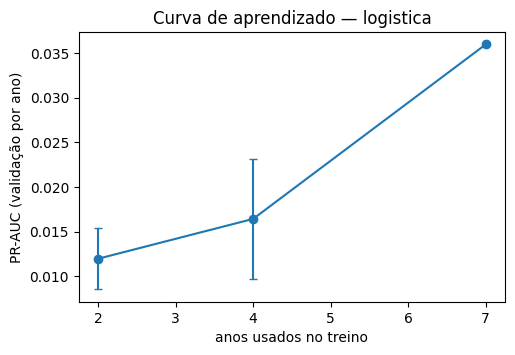

In [12]:
RODAR_CURVA_APRENDIZADO = True            # ~10 min; desligue para economizar tempo
if RODAR_CURVA_APRENDIZADO:
    ca = mod.curva_aprendizado(base, ALVO, FEATURES_A, escolhido, ks=(2, 4, 7), repeticoes=2)
    resumo_ca = ca.groupby("anos_treino")[["pr_auc", "recall_top5"]].agg(["mean", "std"]).round(4)
    display(resumo_ca)
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    m_ = ca.groupby("anos_treino")["pr_auc"].mean(); s_ = ca.groupby("anos_treino")["pr_auc"].std().fillna(0)
    ax.errorbar(m_.index, m_.values, yerr=s_.values, marker="o", capsize=3)
    ax.set_xlabel("anos usados no treino"); ax.set_ylabel("PR-AUC (validação por ano)"); ax.set_title(f"Curva de aprendizado — {escolhido}")
    with mlflow.start_run(run_id=run_comp):
        registrar_fig(fig, "curva_aprendizado")
        registrar_tabela(ca.set_index("anos_treino"), "curva_aprendizado.csv")

## 8. Otimização de hiperparâmetros (Optuna)
**Estratégia.** Otimização bayesiana (TPE, do Optuna) sobre o modelo escolhido, maximizando a **PR-AUC** da validação por ano.

**Por que Optuna e não Grid ou Random Search.** A *Grid Search* testa todas as combinações de uma grade: com 2 a 5 hiperparâmetros contínuos, a grade explode ou fica grossa demais. A *Random Search* sorteia combinações às cegas. O TPE usa o resultado das tentativas anteriores para escolher a próxima, concentrando a busca nas regiões promissoras. Isso importa aqui porque **cada tentativa treina 4 modelos** (um por ano de validação): com o mesmo orçamento, o TPE costuma chegar mais perto do ótimo.

| Item | Valor |
|---|---|
| Técnica | Optuna, amostrador TPE (semente fixa) |
| Número de tentativas | **30** (`N_TRIALS`) |
| Métrica otimizada | PR-AUC (média da validação por ano) |
| Validação dentro da busca | Deixando um ano de fora, só com 2014–2017 |
| Avaliação final | Teste cronológico 2018–2021, nunca visto pela busca |
| Espaço de busca | Por modelo, na função `sugerir` abaixo. Logística: `C` de 0,001 a 10 (escala log) e `class_weight` (nenhum ou *balanced*); árvores: profundidade, tamanho mínimo da folha e peso dos positivos; AdaBoost: também número de estimadores e taxa de aprendizado |

**Cuidado contra otimismo.** Com ~78 dias de evento, é fácil "ajustar os hiperparâmetros ao acaso". Por isso:
1. a busca usa **só os anos 2014–2017** (validação por ano dentro deles);
2. os melhores parâmetros são então avaliados no **teste cronológico 2018–2021**, que a busca nunca viu, e comparados com os parâmetros padrão;
3. só adotamos os parâmetros otimizados se **melhorarem a PR-AUC no teste cronológico**; caso contrário, mantemos os padrão. O teste tem apenas ~25 eventos, então o resultado é um indício, não uma prova.

Para acelerar, a busca treina com 25% dos negativos (o ranking dos positivos não muda); a avaliação final usa os dados completos. Cada tentativa é uma *run* aninhada no MLflow.

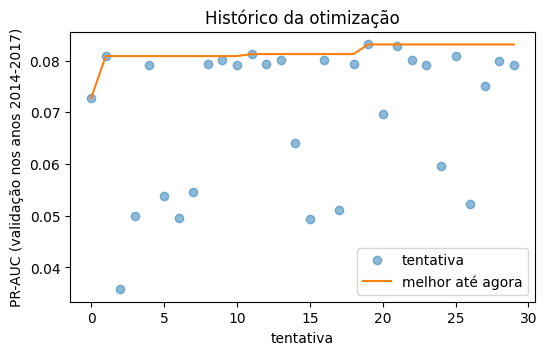

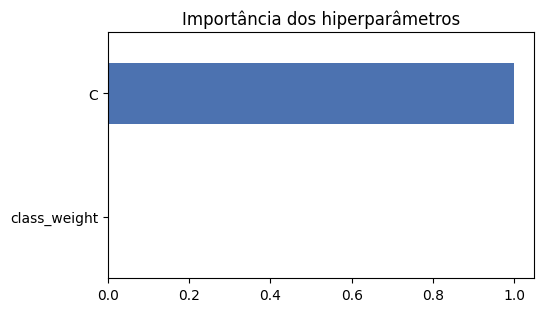

Melhor PR-AUC na busca: 0.0831
Melhores parâmetros: {'C': 0.1656142510824168, 'class_weight': None}


In [13]:
N_TRIALS = 30
FRAC_NEG_TUNING = 0.25
ANOS_TUNING = [2014, 2015, 2016, 2017]
ANOS_TESTE = [2018, 2019, 2020, 2021]

def sugerir(trial, nome):
    if nome == "logistica":
        return {"C": trial.suggest_float("C", 1e-3, 10, log=True),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}
    if nome == "arvore":
        return {"max_depth": trial.suggest_int("max_depth", 2, 10),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 50, 2000, log=True),
                "peso_pos_exp": trial.suggest_float("peso_pos_exp", 0.2, 1.0)}
    if nome == "adaboost":
        return {"n_estimators": trial.suggest_int("n_estimators", 50, 400, step=50),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 1.0, log=True),
                "max_depth": trial.suggest_int("max_depth", 1, 3),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 50, 1000, log=True),
                "peso_pos_exp": trial.suggest_float("peso_pos_exp", 0.2, 1.0)}
    if nome == "floresta":
        return {"max_depth": trial.suggest_int("max_depth", 3, 14),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 500, log=True),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
                "max_samples": trial.suggest_float("max_samples", 0.05, 0.5)}
    return {"max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "max_iter": trial.suggest_int("max_iter", 100, 400, step=50),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 50, 600, log=True),
            "l2": trial.suggest_float("l2", 1e-2, 20, log=True),
            "peso_pos_exp": trial.suggest_float("peso_pos_exp", 0.2, 1.0)}

def objetivo(trial):
    params = sugerir(trial, escolhido)
    res = mod.validar_loyo(base, ALVO, FEATURES_A, escolhido, params, anos=ANOS_TUNING, frac_neg_treino=FRAC_NEG_TUNING)
    score = res["global"]["pr_auc"]
    with mlflow.start_run(run_name=f"trial_{trial.number:03d}", nested=True):
        mlflow.log_params({f"hp_{k}": v for k, v in params.items()})
        mlflow.log_metrics({"pr_auc_cv": float(score), "recall_top5_cv": float(res["global"]["recall_top5"])})
    return score

with mlflow.start_run(run_name=f"otimizacao_{escolhido}") as pai:
    id_otim = pai.info.run_id
    mlflow.set_tags({"etapa": "otimizacao", "modelo": escolhido, "ferramenta": "optuna-TPE"})
    mlflow.log_params({"n_trials": N_TRIALS, "frac_negativos_busca": FRAC_NEG_TUNING, "anos_busca": str(ANOS_TUNING),
                       "anos_teste_cronologico": str(ANOS_TESTE), "objetivo": "maximizar pr_auc (validacao por ano)"})
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=mod.SEMENTE))
    study.optimize(objetivo, n_trials=N_TRIALS)
    melhores = dict(study.best_params)
    mlflow.log_metric("melhor_pr_auc_cv", float(study.best_value))
    mlflow.log_params({f"melhor_{k}": v for k, v in melhores.items()})

    trials = study.trials_dataframe()
    registrar_tabela(trials.set_index("number"), "optuna_tentativas.csv")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(trials["number"], trials["value"], "o", alpha=0.5, label="tentativa"); ax.plot(trials["number"], trials["value"].cummax(), "-", label="melhor até agora")
    ax.set_xlabel("tentativa"); ax.set_ylabel("PR-AUC (validação nos anos 2014-2017)"); ax.set_title("Histórico da otimização"); ax.legend()
    registrar_fig(fig, "optuna_historico")
    try:
        imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
        fig, ax = plt.subplots(figsize=(5.5, 3.2)); imp.plot(kind="barh", ax=ax, color="#4c72b0"); ax.set_title("Importância dos hiperparâmetros")
        registrar_fig(fig, "optuna_importancia")
    except Exception as e:
        print("importância dos hiperparâmetros indisponível:", e)

print("Melhor PR-AUC na busca:", round(study.best_value, 4)); print("Melhores parâmetros:", melhores)

In [14]:
m_pad, _ = mod.treinar_testar(base, ALVO, FEATURES_A, escolhido, None, ANOS_TUNING, ANOS_TESTE)
m_otim, _ = mod.treinar_testar(base, ALVO, FEATURES_A, escolhido, melhores, ANOS_TUNING, ANOS_TESTE)
tab_h = pd.DataFrame({"parâmetros padrão": m_pad, "parâmetros otimizados": m_otim}).T
display(tab_h[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5", "f1_top5"]].round(4))

ADOTAR = bool(m_otim["pr_auc"] > m_pad["pr_auc"])
PARAMS_FINAIS = melhores if ADOTAR else {}
print("Parâmetros otimizados superam os padrão no teste cronológico?", "SIM — serão adotados" if ADOTAR else "NÃO — mantém os padrão")
with mlflow.start_run(run_id=id_otim):
    mlflow.log_metrics({"teste_cron_pr_auc_padrao": float(m_pad["pr_auc"]), "teste_cron_pr_auc_otimizado": float(m_otim["pr_auc"]),
                        "teste_cron_recall_top5_padrao": float(m_pad["recall_top5"]), "teste_cron_recall_top5_otimizado": float(m_otim["recall_top5"])})
    mlflow.set_tag("parametros_otimizados_adotados", str(ADOTAR))
    registrar_tabela(tab_h, "optuna_teste_cronologico.csv")

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5,f1_top5
parâmetros padrão,0.0262,0.8421,0.16,0.32,0.0015,0.0029
parâmetros otimizados,0.0326,0.9205,0.28,0.60,0.0028,0.0055


Parâmetros otimizados superam os padrão no teste cronológico? SIM — serão adotados


**Como ler:** se os parâmetros otimizados não superam os padrão fora da amostra, a busca apenas **se ajustou ao acaso** dos anos 2014–2017 — um resultado legítimo e comum quando há poucos eventos. Nesse caso, mantemos os padrão e documentamos isso.

## 9. Avaliação final, cenário B e modelo final
Com a decisão sobre os hiperparâmetros tomada, repetimos a validação por ano com a configuração final. Também avaliamos o **cenário B** (sem a chuva do dia): ele serve de **modelo reserva** para quando a chuva do dia não estiver disponível (por exemplo, falha do pluviômetro ou da previsão).

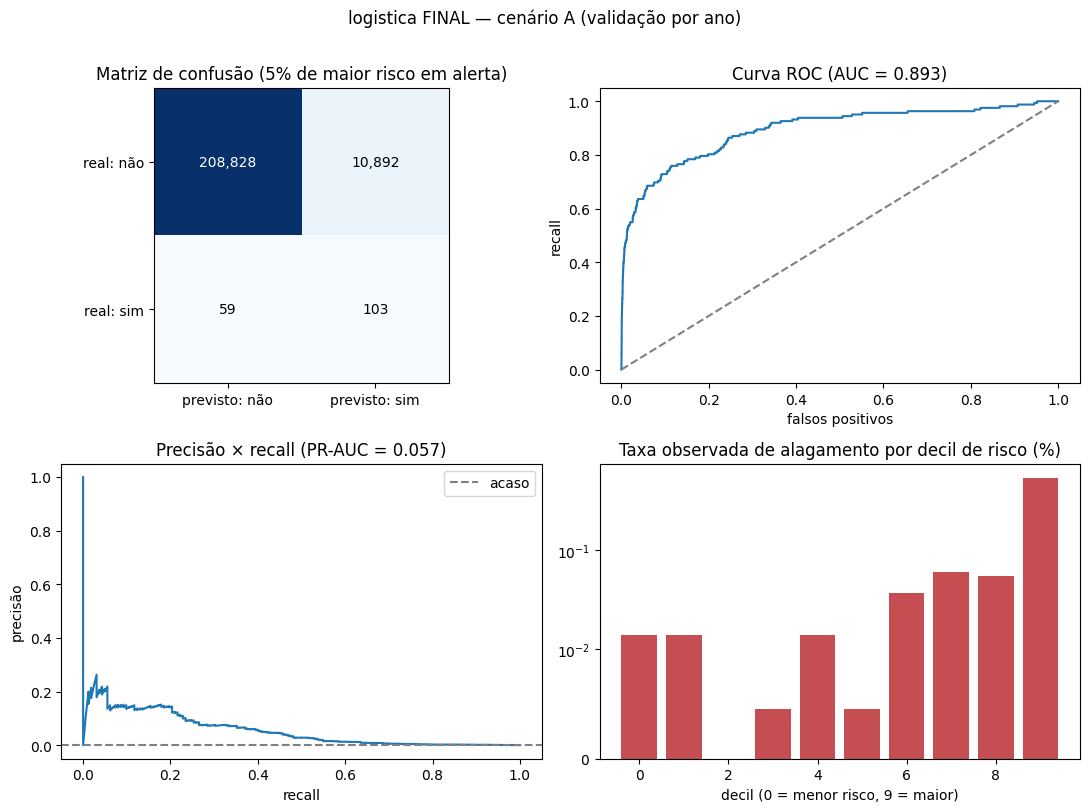

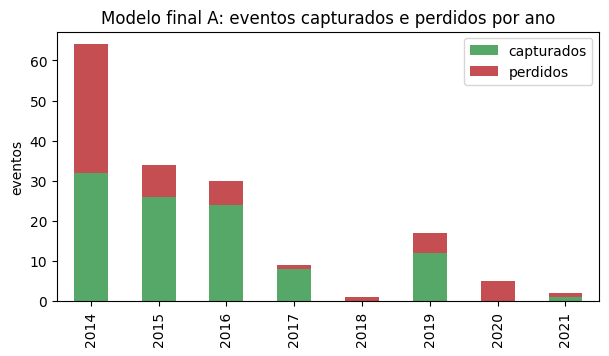

,linhas,eventos,taxa_%,% dos eventos
nivel,,,,
3,1100,64,5.818,39.5
2,3298,24,0.728,14.8
1,10994,23,0.209,14.2
0,204490,51,0.025,31.5


{'pr_auc': 0.057, 'roc_auc': 0.8934, 'taxa_base': 0.0007, 'recall_top1': 0.4753, 'precisao_top1': 0.035, 'f1_top1': 0.0653, 'recall_top5': 0.6358, 'precisao_top5': 0.0094, 'f1_top5': 0.0185}


In [15]:
if PARAMS_FINAIS:
    res_A = mod.validar_loyo(base, ALVO, FEATURES_A, escolhido, PARAMS_FINAIS, calcular_treino=True)
else:
    res_A = resultados[escolhido]
oof_A = res_A["oof"].loc[base.index]
p_A = oof_A["p"].values

cortes_A = {"top5": float(np.quantile(p_A, 0.95)), "niveis": [float(np.quantile(p_A, q)) for q in (0.93, 0.98, 0.995)]}
nivel = np.digitize(p_A, cortes_A["niveis"])
niveis = pd.DataFrame({"nivel": nivel, "y": y}).groupby("nivel").agg(linhas=("y", "size"), eventos=("y", "sum"))
niveis["taxa_%"] = (100 * niveis["eventos"] / niveis["linhas"]).round(3)
niveis["% dos eventos"] = (100 * niveis["eventos"] / niveis["eventos"].sum()).round(1)

with mlflow.start_run(run_name=f"final_{escolhido}_cenarioA") as r:
    id_final_A = r.info.run_id
    mlflow.set_tags({"etapa": "avaliacao_final", "cenario": "A", "modelo": escolhido})
    mlflow.log_params({**{f"hp_{k}": v for k, v in res_A["params"].items()}, "hiperparametros_otimizados": str(ADOTAR), "dataset_sha256_16": SHA})
    mlflow.log_metrics(limpa(res_A["global"]))
    registrar_fig(painel_modelo(f"{escolhido} FINAL — cenário A (validação por ano)", oof_A["y"].values, p_A), "painel_final_A")
    registrar_fig(figura_erro_por_ano("Modelo final A: eventos capturados e perdidos por ano", oof_A), "erro_por_ano_final_A")
    registrar_tabela(niveis, "niveis_de_risco_A.csv")
display(niveis.sort_index(ascending=False))
print({k: round(v, 4) for k, v in res_A["global"].items()})

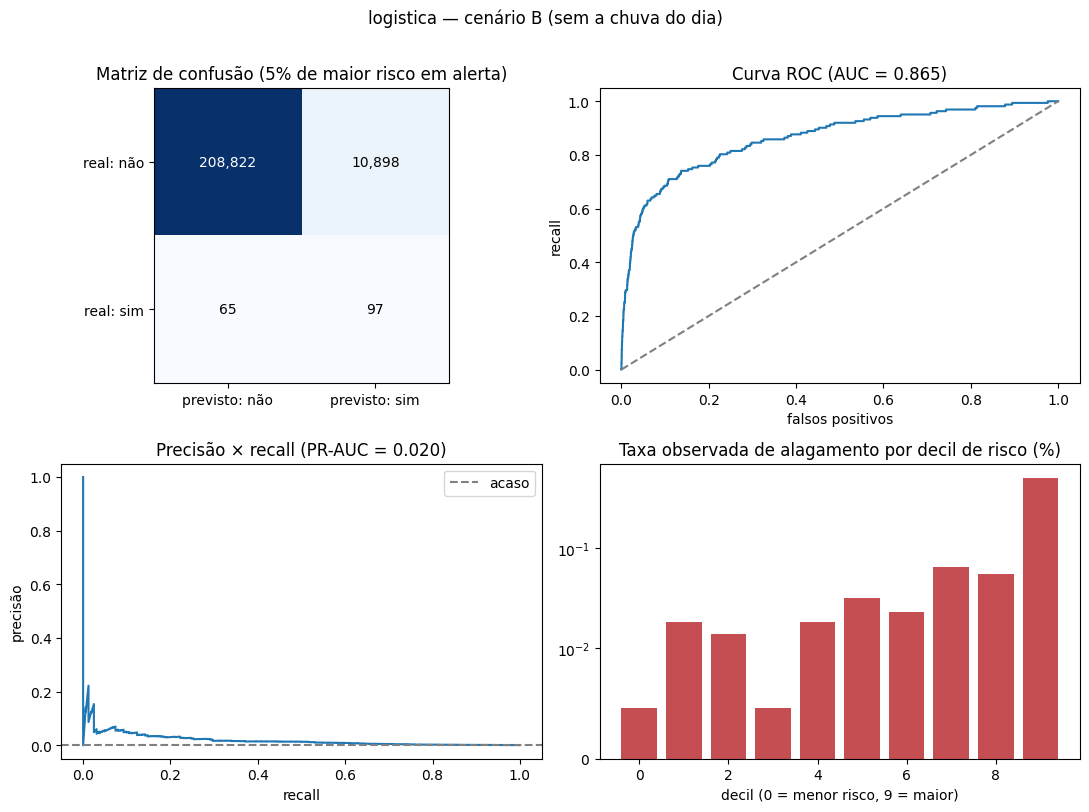

,pr_auc,roc_auc,recall_top1,recall_top5,precisao_top5,f1_top5
A (chuva do dia conhecida),0.0570,0.8934,0.4753,0.6358,0.0094,0.0185
B (sem a chuva do dia),0.0202,0.8650,0.2901,0.5988,0.0088,0.0174


In [16]:
res_B = mod.validar_loyo(base, ALVO, FEATURES_B, escolhido, PARAMS_FINAIS, calcular_treino=True)
oof_B = res_B["oof"].loc[base.index]; p_B = oof_B["p"].values
cortes_B = {"top5": float(np.quantile(p_B, 0.95)), "niveis": [float(np.quantile(p_B, q)) for q in (0.93, 0.98, 0.995)]}

with mlflow.start_run(run_name=f"final_{escolhido}_cenarioB") as r:
    id_final_B = r.info.run_id
    mlflow.set_tags({"etapa": "avaliacao_final", "cenario": "B", "modelo": escolhido})
    mlflow.log_params({**{f"hp_{k}": v for k, v in res_B["params"].items()}, "n_features": len(FEATURES_B) + 1})
    mlflow.log_metrics(limpa(res_B["global"]))
    registrar_fig(painel_modelo(f"{escolhido} — cenário B (sem a chuva do dia)", oof_B["y"].values, p_B), "painel_final_B")

comp_AB = pd.DataFrame({"A (chuva do dia conhecida)": res_A["global"], "B (sem a chuva do dia)": res_B["global"]}).T
display(comp_AB[["pr_auc", "roc_auc", "recall_top1", "recall_top5", "precisao_top5", "f1_top5"]].round(4))

### Salvando e registrando os modelos
Treinamos os modelos finais com **todos os anos (2014–2021)** e os registramos no MLflow (*Model Registry*) com os cortes de risco calculados na validação. É este artefato que a API de inferência vai carregar. Verificamos em seguida que o modelo salvo reproduz as previsões do modelo em memória.

In [17]:
def salvar_modelo(cenario, feats, cortes, nome_registro, res, run_id_avaliacao):
    m = mod.ajustar_final(base, ALVO, feats, escolhido, PARAMS_FINAIS)
    m.cortes_ = cortes
    caminho = MODELOS_DIR / f"{nome_registro}.joblib"
    joblib.dump(m, caminho)
    ficha = {"nome": nome_registro, "cenario": cenario, "modelo": escolhido, "hiperparametros": res["params"],
             "alvo": ALVO, "features": feats + ["propensao_bairro"], "entrada_api": feats + ["bairro"],
             "cortes": cortes, "metricas_validacao_por_ano": limpa(res["global"]),
             "dataset_sha256_16": SHA, "anos_treino": sorted(int(a) for a in base["ano"].unique()),
             "avaliacao_run_id": run_id_avaliacao, "gerado_em": datetime.datetime.now().isoformat(timespec="seconds")}
    registrar_json(ficha, f"ficha_{nome_registro}.json")
    mlflow.log_artifact(str(caminho), artifact_path="modelos")
    try:
        info = registrar_modelo(m, f"modelo_{cenario}", base[feats + ["bairro"]].head(5))
        versao = mlflow.register_model(info.model_uri, nome_registro)
        try:
            _cli.set_registered_model_alias(nome_registro, "campeao", versao.version)
        except Exception:
            pass
        print(f"registrado: {nome_registro} v{versao.version}")
    except Exception as e:
        print(f"AVISO: não foi possível registrar '{nome_registro}' no Model Registry ({type(e).__name__}: {e}). O arquivo {caminho.name} foi salvo.")
    return m, caminho

with mlflow.start_run(run_name="modelo_final") as r:
    id_modelo_final = r.info.run_id
    mlflow.set_tags({"etapa": "modelo_final", "modelo": escolhido})
    modelo_A, caminho_A = salvar_modelo("A", FEATURES_A, cortes_A, "risco_alagamento", res_A, id_final_A)
    modelo_B, caminho_B = salvar_modelo("B", FEATURES_B, cortes_B, "risco_alagamento_cenario_B", res_B, id_final_B)

# verificacao: o modelo salvo reproduz as previsoes do modelo em memoria
amostra = base.sample(5000, random_state=mod.SEMENTE)
recarregado = joblib.load(caminho_A)
print("modelo salvo reproduz as previsões:", bool(np.allclose(modelo_A.prever(amostra), recarregado.prever(amostra))))
print("níveis de risco previstos (0-3) na amostra:", np.bincount(recarregado.nivel(amostra), minlength=4))

2026/11/25 12:16:22 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/25 12:16:22 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/25 12:16:22 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


Registered model 'risco_alagamento' already exists. Creating a new version of this model...
Created version '3' of model 'risco_alagamento'.


registrado: risco_alagamento v3


2026/11/25 12:16:26 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


registrado: risco_alagamento_cenario_B v3
modelo salvo reproduz as previsões: True
níveis de risco previstos (0-3) na amostra: [4602  288   76   34]


Registered model 'risco_alagamento_cenario_B' already exists. Creating a new version of this model...
Created version '3' of model 'risco_alagamento_cenario_B'.


### Importância das variáveis
Duas leituras complementares:
1. **Coeficientes do modelo final** (treinado com 2014–2021). Na regressão logística as variáveis entram padronizadas, então o tamanho do coeficiente é comparável entre elas: é o efeito de **um desvio padrão** da variável (já em `log1p`, no caso das chuvas) no logaritmo da chance de alagamento. O sinal diz a direção.
2. **Importância por permutação, fora da amostra:** treinamos com 2014–2017 e, no teste cronológico 2018–2021, embaralhamos uma variável por vez (10 repetições) e medimos quanto a PR-AUC e a ROC-AUC caem. Se a queda é ~0, o modelo não depende daquela variável. Fazemos isso para o modelo escolhido e para o AdaBoost (maior PR-AUC da comparação), para ver se os dois se apoiam nas mesmas variáveis. Com ~25 eventos no teste a queda da PR-AUC é ruidosa; a da ROC-AUC é mais estável.

,coeficiente
chuva_dia_mm,0.965
sem_chuva_no_dia,0.585
chuva_d1_mm,0.406
dias_desde_ultimo_alag_estrito,-0.401
chuva_max_1h_mm,0.316
n_alag_estrito_bairro_365d,0.281
propensao_bairro,0.270
n_alag_bairro_365d,-0.246
pct_pontos_abaixo_5m,-0.235
mare_subindo_na_hora_pico,0.226


logistica: teste cronológico sem permutar PR-AUC=0.0326 ROC-AUC=0.9205


adaboost: teste cronológico sem permutar PR-AUC=0.0112 ROC-AUC=0.8519


logistica                   adaboost              
                               queda_pr_auc queda_roc_auc queda_pr_auc queda_roc_auc
variavel                                                                            
chuva_dia_mm                         0.0164        0.1202       0.0081        0.0333
propensao_bairro                     0.0170        0.0166       0.0044        0.0479
mes                                 -0.0029        0.0144      -0.0024       -0.0022
chuva_d1_mm                          0.0132        0.0142       0.0008        0.0254
mare_na_hora_pico_chuva_m            0.0185        0.0142       0.0000        0.0000
mare_min_dia_m                       0.0056        0.0089      -0.0003       -0.0010
chuva_max_1h_mm                     -0.0071        0.0085      -0.0004        0.0008
dias_desde_ultimo_alag               0.0106        0.0039      -0.0012        0.0006
area_km2                             0.0038        0.0034      -0.0002        0.0038
n_bairros_alag_dia_anterior          0.0132        0.0032       0.0004       -0.0000
dist_faixa_min_m                     0.0025        0.0025       0.0003        0.0033
dist_faixa_media_m                   0.0028        0.0022       0.0000        0.0000
dias_desde_ultimo_alag_estrito       0.0161        0.0018       0.0017       -0.0012
n_alag_estrito_bairro_365d          -0.0003        0.0016       0.0000        0.0000
chuva_ult7d_mm                      -0.0029        0.0015       0.0000        0.0000

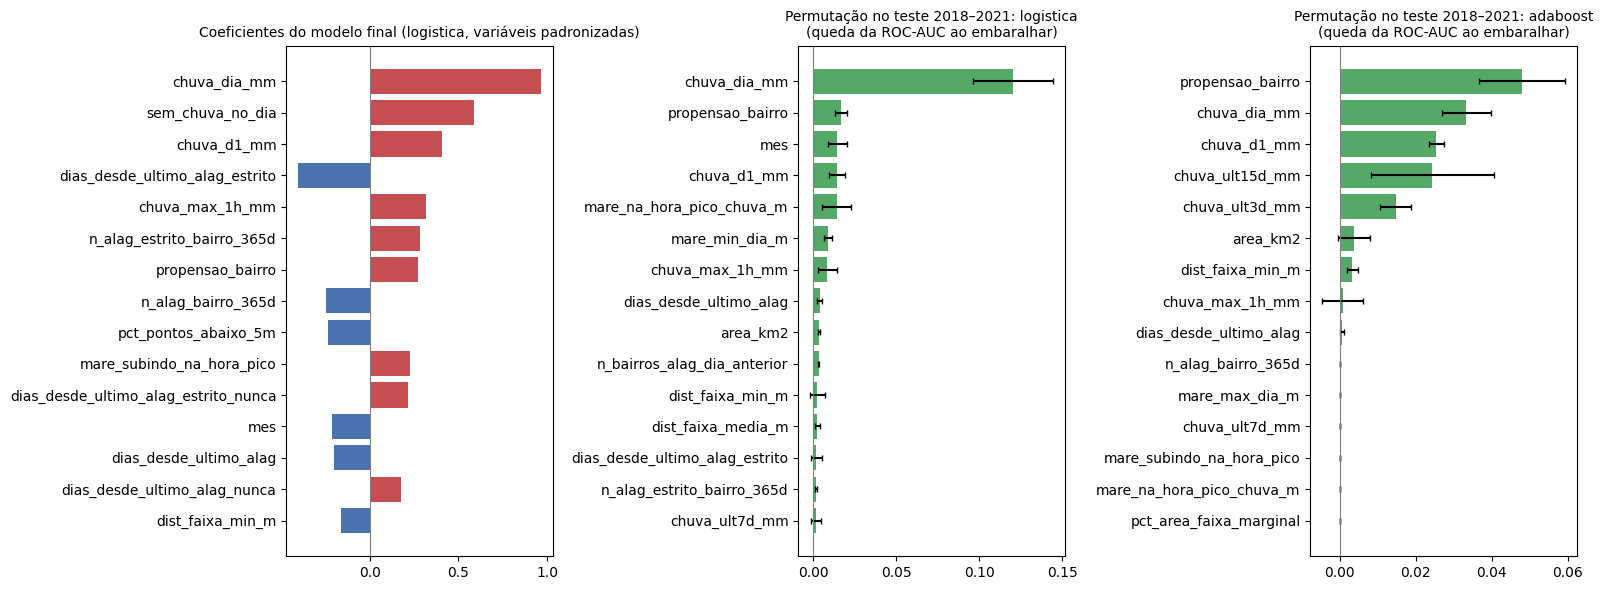

In [18]:
est_final = modelo_A.estimador
colunas_final = modelo_A.preparador.colunas_
if hasattr(getattr(est_final, "m_", None), "coef_"):
    imp_final = pd.Series(est_final.m_.coef_[0], index=colunas_final, name="coeficiente")
    titulo_final = f"Coeficientes do modelo final ({escolhido}, variáveis padronizadas)"
else:
    imp_final = pd.Series(est_final.m_.feature_importances_, index=colunas_final, name="importancia")
    titulo_final = f"Importância das variáveis no modelo final ({escolhido})"
imp_final = imp_final.reindex(imp_final.abs().sort_values(ascending=False).index)
display(imp_final.head(15).round(3).to_frame())

perm = {}
for nome_p, params_p in [(escolhido, PARAMS_FINAIS or None), ("adaboost", None)]:
    if nome_p in perm:
        continue
    perm[nome_p], base_p = mod.importancia_permutacao(base, ALVO, FEATURES_A, nome_p, params_p, ANOS_TUNING, ANOS_TESTE, repeticoes=10)
    print(f"{nome_p}: teste cronológico sem permutar PR-AUC={base_p['pr_auc']:.4f} ROC-AUC={base_p['roc_auc']:.4f}")
tab_perm = pd.concat({n: t[["queda_pr_auc", "queda_roc_auc"]] for n, t in perm.items()}, axis=1)
tab_perm = tab_perm.sort_values((escolhido, "queda_roc_auc"), ascending=False)
display(tab_perm.head(15).round(4))

top = imp_final.head(15)[::-1]
fig, ax = plt.subplots(1, 1 + len(perm), figsize=(6 + 5 * len(perm), 6))
ax[0].barh(top.index, top.values, color=np.where(top.values > 0, "#c44e52", "#4c72b0"))
ax[0].axvline(0, color="gray", lw=0.8); ax[0].set_title(titulo_final, fontsize=10)
for a, (n, t) in zip(ax[1:], perm.items()):
    t15 = t.sort_values("queda_roc_auc", ascending=False).head(15)[::-1]
    a.barh(t15.index, t15["queda_roc_auc"], xerr=t15["queda_roc_auc_desvio"], color="#55a868", capsize=2)
    a.axvline(0, color="gray", lw=0.8)
    a.set_title(f"Permutação no teste 2018–2021: {n}\n(queda da ROC-AUC ao embaralhar)", fontsize=10)
fig.tight_layout()
with mlflow.start_run(run_id=id_modelo_final):
    registrar_fig(fig, "importancia_variaveis")
    registrar_tabela(imp_final.to_frame(), "importancia_coeficientes_final.csv")
    registrar_tabela(pd.concat(perm, axis=1), "importancia_permutacao.csv")

**Interpretação:**
- **A chuva do dia domina.** É o maior coeficiente (+0,97 por desvio padrão do `log1p` da chuva) e a variável que mais derruba o desempenho quando embaralhada (queda de 0,12 na ROC-AUC da logística). Isso explica por que o cenário B, sem a chuva do dia, perde tanto (PR-AUC 0,057 → 0,020).
- **Depois vêm o bairro e o histórico:** a propensão do bairro, a chuva do dia anterior e o tempo desde o último alagamento (sinal negativo: quanto mais tempo sem alagar, menor o risco). A maré na hora do pico da chuva também pesa na permutação da logística. É coerente com a hipótese de que maré alta dificulta o escoamento.
- **Os dois modelos concordam no essencial:** na logística e no AdaBoost, as duas variáveis mais importantes são a chuva do dia e a propensão do bairro. O AdaBoost usa menos variáveis: o relevo e a maré quase não aparecem nele.
- **Cuidado ao ler os coeficientes um a um.** Variáveis muito correlacionadas dividem o peso entre si e podem ganhar sinais contraintuitivos. Exemplos: `sem_chuva_no_dia` positivo junto com a própria chuva do dia, e `n_alag_bairro_365d` negativo ao lado de `n_alag_estrito_bairro_365d` positivo. A leitura confiável é a do **grupo**: chuva, histórico do bairro e maré. A permutação, que embaralha uma variável por vez, mede melhor o que o modelo realmente usa.
- **O relevo** (altitude, faixa marginal) aparece pouco. Ele provavelmente já está embutido na propensão histórica do bairro, que mede onde costuma alagar.

## Apêndice A — Árvores regularizadas mudam a conclusão?

**Motivação.** A seção 7.1 mostrou que a floresta e o boosting **decoram o treino** (PR-AUC de 0,24 e 0,48 no treino contra ~0,02–0,03 na validação), enquanto a logística não. Como a otimização da seção 8 só foi feita no modelo escolhido, não sabemos se árvores **fortemente regularizadas** seriam competitivas. Este apêndice responde a essa pergunta sem alterar o resultado principal do notebook.

**Regras fixadas antes de rodar** (para não "pescar" o melhor número depois de ver os resultados):
1. O espaço de busca **só restringe** as árvores: profundidade 2 a 4, folhas de 200 a 3.000 linhas, poucas iterações e regularização forte. O objetivo é testar regularização severa, não achar o melhor número a qualquer custo.
2. A busca usa só os anos **2014–2017** (validação por ano dentro deles). A avaliação é no **teste cronológico 2018–2021**, que a busca nunca viu — o mesmo protocolo da seção 8.
3. A comparação é contra o **modelo escolhido já otimizado**, nas mesmas condições.
4. Só consideramos trocar de modelo se a árvore otimizada **vencer em pelo menos 95% das reamostras de dias** (PR-AUC) com diferença média positiva. Qualquer outro resultado é empate e **mantém** o modelo escolhido.
5. Este apêndice **não altera** os modelos salvos nem registrados. Se uma árvore vencer, o notebook apenas recomenda reavaliar — a troca seria uma decisão do grupo.

**Chave de execução:** `RODAR_APENDICE_ARVORES` (tempo estimado: 10 a 20 minutos). Todos os resultados vão para o MLflow, na *run* `apendice_arvores_regularizadas`.

In [19]:
RODAR_APENDICE_ARVORES = True
N_TRIALS_ARV = 20

def sugerir_arvore(trial, nome):
    if nome == "floresta":
        return {"max_depth": trial.suggest_int("max_depth", 2, 4),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 200, 2000, log=True),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3]),
                "max_samples": trial.suggest_float("max_samples", 0.05, 0.3)}
    return {"max_depth": trial.suggest_int("max_depth", 2, 3),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "max_iter": trial.suggest_int("max_iter", 50, 200, step=25),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 300, 3000, log=True),
            "l2": trial.suggest_float("l2", 1.0, 50.0, log=True),
            "peso_pos_exp": trial.suggest_float("peso_pos_exp", 0.1, 0.7)}

arv_otimizados, id_arv = {}, None
if RODAR_APENDICE_ARVORES:
    with mlflow.start_run(run_name="apendice_arvores_regularizadas") as pai_arv:
        id_arv = pai_arv.info.run_id
        mlflow.set_tags({"etapa": "apendice_arvores", "ferramenta": "optuna-TPE"})
        mlflow.log_params({"n_trials_por_modelo": N_TRIALS_ARV, "anos_busca": str(ANOS_TUNING),
                           "anos_teste_cronologico": str(ANOS_TESTE), "espaco": "arvores rasas e folhas grandes (regularizacao forte)"})
        for nome_arv in ["floresta", "boosting"]:
            def objetivo_arv(trial, nome_arv=nome_arv):
                params = sugerir_arvore(trial, nome_arv)
                res = mod.validar_loyo(base, ALVO, FEATURES_A, nome_arv, params, anos=ANOS_TUNING)
                score = res["global"]["pr_auc"]
                with mlflow.start_run(run_name=f"{nome_arv}_trial_{trial.number:03d}", nested=True):
                    mlflow.log_params({f"hp_{k}": v for k, v in params.items()})
                    mlflow.log_metrics({"pr_auc_cv": float(score), "recall_top5_cv": float(res["global"]["recall_top5"])})
                return score
            estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=mod.SEMENTE))
            estudo.optimize(objetivo_arv, n_trials=N_TRIALS_ARV)
            arv_otimizados[nome_arv] = dict(estudo.best_params)
            mlflow.log_metric(f"melhor_pr_auc_cv_{nome_arv}", float(estudo.best_value))
            mlflow.log_params({f"melhor_{nome_arv}_{k}": v for k, v in estudo.best_params.items()})
            registrar_tabela(estudo.trials_dataframe().set_index("number"), f"apendice_tentativas_{nome_arv}.csv")
            print(f"{nome_arv}: melhor PR-AUC na busca = {estudo.best_value:.4f} | parâmetros = {arv_otimizados[nome_arv]}")

floresta: melhor PR-AUC na busca = 0.0325 | parâmetros = {'max_depth': 2, 'min_samples_leaf': 209, 'max_features': 'sqrt', 'max_samples': 0.13406744054848843}


boosting: melhor PR-AUC na busca = 0.1320 | parâmetros = {'max_depth': 2, 'learning_rate': 0.04708402017648813, 'max_iter': 175, 'min_samples_leaf': 440, 'l2': 1.1438878622395914, 'peso_pos_exp': 0.3347159823870349}


### Avaliação fora da amostra (teste cronológico 2018–2021)
Para cada modelo, comparamos os parâmetros **padrão** e os **otimizados**. As colunas de treino (`treino_*`) mostram o quanto cada modelo decora: um grande salto entre treino e teste indica sobreajuste; se a regularização funcionou, o salto deve diminuir.

,treino_pr_auc,teste_pr_auc,treino_recall_top5,teste_recall_top5,teste_roc_auc,teste_precisao_top5,gap_pr_auc
modelo,,,,,,,
logistica (padrão),0.0564,0.0262,0.7299,0.32,0.8421,0.0015,0.0302
logistica (otimizado),0.1184,0.0326,0.6934,0.60,0.9205,0.0028,0.0858
floresta (padrão),0.2677,0.0090,1.0000,0.56,0.9077,0.0026,0.2587
floresta (regularizada),0.1301,0.0067,0.6350,0.56,0.8881,0.0026,0.1234
boosting (padrão),0.4599,0.0143,1.0000,0.48,0.8346,0.0022,0.4455
boosting (regularizado),0.2568,0.0149,0.8905,0.56,0.8745,0.0026,0.2419


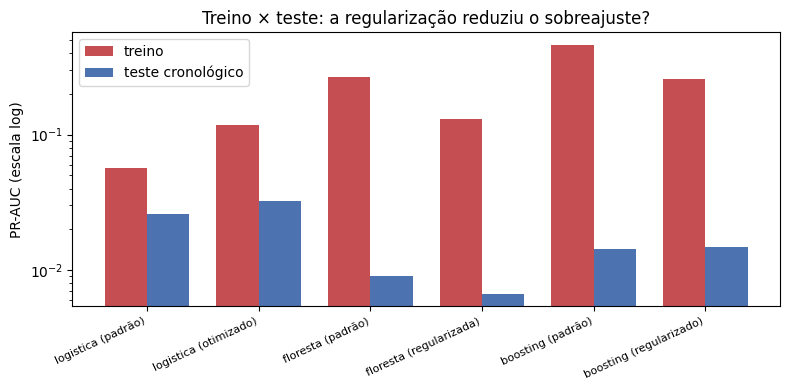

In [20]:
if RODAR_APENDICE_ARVORES:
    configs = [(f"{escolhido} (padrão)", escolhido, None),
               (f"{escolhido} (otimizado)", escolhido, PARAMS_FINAIS or None),
               ("floresta (padrão)", "floresta", None),
               ("floresta (regularizada)", "floresta", arv_otimizados["floresta"]),
               ("boosting (padrão)", "boosting", None),
               ("boosting (regularizado)", "boosting", arv_otimizados["boosting"])]
    linhas_arv, preds_arv, refs_idx = [], {}, None
    for rotulo, nome_m, params_m in configs:
        m, r = mod.treinar_testar(base, ALVO, FEATURES_A, nome_m, params_m, ANOS_TUNING, ANOS_TESTE, devolver_treino=True)
        preds_arv[rotulo] = r
        if refs_idx is None:
            refs_idx = r["idx_te"]
        assert (r["idx_te"] == refs_idx).all(), "as linhas de teste deveriam ser as mesmas"
        linhas_arv.append({"modelo": rotulo, "treino_pr_auc": r["metricas_treino"]["pr_auc"], "teste_pr_auc": m["pr_auc"],
                           "treino_recall_top5": r["metricas_treino"]["recall_top5"], "teste_recall_top5": m["recall_top5"],
                           "teste_roc_auc": m["roc_auc"], "teste_precisao_top5": m["precisao_top5"]})
    tab_arv = pd.DataFrame(linhas_arv).set_index("modelo")
    tab_arv["gap_pr_auc"] = tab_arv["treino_pr_auc"] - tab_arv["teste_pr_auc"]
    display(tab_arv.round(4))

    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(tab_arv)); larg = 0.38
    ax.bar(x - larg / 2, tab_arv["treino_pr_auc"], larg, label="treino", color="#c44e52")
    ax.bar(x + larg / 2, tab_arv["teste_pr_auc"], larg, label="teste cronológico", color="#4c72b0")
    ax.set_xticks(x); ax.set_xticklabels(tab_arv.index, rotation=25, ha="right", fontsize=8)
    ax.set_yscale("log"); ax.set_ylabel("PR-AUC (escala log)"); ax.set_title("Treino × teste: a regularização reduziu o sobreajuste?"); ax.legend()
    fig.tight_layout()
    with mlflow.start_run(run_id=id_arv):
        registrar_fig(fig, "apendice_treino_vs_teste")
        registrar_tabela(tab_arv, "apendice_comparacao_holdout.csv")

### Decisão pela regra fixada
Reamostramos **dias inteiros** do período de teste (os eventos se agrupam por tempestade) e medimos, para cada árvore regularizada, em quantas reamostras ela supera o modelo escolhido otimizado. **Atenção:** o teste cronológico tem poucos eventos (~25), então o poder estatístico é baixo — um empate é o resultado mais provável e **não** prova que as árvores são iguais ao modelo escolhido, só que estes dados não permitem distingui-las.

In [21]:
if RODAR_APENDICE_ARVORES:
    ref = f"{escolhido} (otimizado)"
    y_te = preds_arv[ref]["y_te"]
    datas_te = base.loc[refs_idx, "data"].values
    scores_arv = {k: v["p_te"] for k, v in preds_arv.items()}
    ap_a, rc_a = mod.bootstrap_dias(datas_te, y_te, scores_arv, B=300)

    linhas_dec, decisao = [], {}
    for rotulo in ["floresta (regularizada)", "boosting (regularizado)"]:
        d_ap = ap_a[rotulo] - ap_a[ref]; d_rc = rc_a[rotulo] - rc_a[ref]
        vence = float((d_ap > 0).mean())
        decisao[rotulo] = bool(vence >= 0.95 and d_ap.mean() > 0)
        linhas_dec.append({"modelo": rotulo, "dif PR-AUC (média)": d_ap.mean(), "IC95 inf": np.percentile(d_ap, 2.5),
                           "IC95 sup": np.percentile(d_ap, 97.5), "vence em % das reamostras": 100 * vence,
                           "dif recall@top5 (média)": d_rc.mean()})
    tab_dec = pd.DataFrame(linhas_dec).set_index("modelo")
    print(f"Diferenças em relação a: {ref}"); display(tab_dec.round(4))

    if any(decisao.values()):
        vencedoras = [k for k, v in decisao.items() if v]
        resultado = f"{vencedoras} superou o modelo escolhido de forma clara. Recomenda-se REAVALIAR a escolha (decisão do grupo); os modelos salvos NÃO foram alterados."
    else:
        resultado = f"Nenhuma árvore regularizada superou claramente '{ref}'. Resultado: EMPATE — o modelo escolhido é mantido."
    print("\n" + resultado)
    with mlflow.start_run(run_id=id_arv):
        mlflow.set_tag("resultado_apendice", resultado)
        for rotulo, vence_ in decisao.items():
            mlflow.set_tag(f"supera_claramente_{rotulo.split()[0]}", str(vence_))
        registrar_tabela(tab_dec, "apendice_decisao.csv")

Diferenças em relação a: logistica (otimizado)


,dif PR-AUC (média),IC95 inf,IC95 sup,vence em % das reamostras,dif recall@top5 (média)
modelo,,,,,
floresta (regularizada),-0.0287,-0.0816,0.0034,7.3333,-0.0078
boosting (regularizado),-0.0224,-0.0781,0.0129,19.6667,-0.0346



Nenhuma árvore regularizada superou claramente 'logistica (otimizado)'. Resultado: EMPATE — o modelo escolhido é mantido.


### Como interpretar
- **Sobreajuste:** compare `gap_pr_auc` dos modelos "padrão" com os "regularizados". Se o gap despencou, a regularização funcionou, mas o que importa é se o **teste** melhorou — menos decoração não garante mais acerto.
- **Empate é um resultado legítimo.** Significa que, com ~25 eventos no teste, não conseguimos mostrar que árvores regularizadas valem mais do que a regressão logística. Nesse caso mantemos a logística: é mais simples, mais fácil de explicar à Defesa Civil e já está registrada.
- **Se uma árvore vencer:** trate como hipótese a confirmar com os dados de 2022+ (quando houver chuva de APAC/CEMADEN), não como decisão automática.
- **Limite do apêndice:** a busca usou 20 tentativas por modelo e só quatro anos de treino; um espaço maior ou mais dados poderiam mudar o quadro.

## 10. Resumo, limitações e próximos passos

**O que este notebook entrega**
- Protocolo de avaliação definido antes dos experimentos.
- Baseline (regressão logística), três modelos da lista da especificação (árvore de decisão, random forest, AdaBoost) e um modelo adicional (gradient boosting), comparados com métricas apropriadas a evento raro, matriz de confusão, curvas ROC/PR, erro por ano, intervalos de confiança, tabela final com média e desvio de cada métrica, análise de onde o modelo falha e importância das variáveis.
- Otimização de hiperparâmetros com Optuna, avaliada fora da amostra.
- Análise de estabilidade, overfitting e generalização, incluindo o contraste com o *k-fold* estratificado e a curva de aprendizado.
- Modelos finais (cenários A e B) salvos em `modelos/` e registrados no MLflow, com cortes de nível de risco.
- **Apêndice A:** teste de árvores fortemente regularizadas, com regra de decisão fixada antes de rodar, para esclarecer se o sobreajuste das árvores esconde um modelo competitivo.

**Limitações que devem acompanhar qualquer apresentação**
- Só 162 eventos, concentrados em 78 dias: as métricas têm incerteza grande e as diferenças pequenas entre modelos são empate.
- O rótulo é um registro da Defesa Civil, não alagamento medido; a "propensão do bairro" mistura vulnerabilidade real com viés de registro.
- Uma só estação de chuva (INMET A301), com dados até 2021. A chuva do dia é observada, não prevista.
- A precisão nos 5% de maior risco é baixa: a maioria dos alertas não coincide com um registro. O modelo serve para **priorizar**, não para decidir sozinho.

**Próximos passos**
1. **Integração (item 7 do documento):** a API carrega `modelos/risco_alagamento.joblib` (ou o modelo registrado no MLflow) e chama `modelo.prever(df)` com as colunas de `entrada_api` da ficha. O pluviômetro e o simulador só entram nessa etapa, fornecendo a chuva do dia por MQTT.
2. **Airflow:** transformar os notebooks 01 e 02 em tarefas (`preparacao`, `treino`, `avaliacao`, `registro`).
3. **Dados novos:** chuva de 2022+ (APAC/CEMADEN) para um teste de verdade, e a altitude relativa à drenagem (HAND).